# TGP-UTF: Satellite Pose Estimation Pipeline
**Transformer-Guided Geometric Pose Estimation with Uncertainty-Aware Temporal Fusion**

Built for the ISRO/URSC lab test-rig dataset (OAK-D camera + robotic arm, `pose_<timestamp>.jpg` / `.json` pairs).

### What this notebook does
Your raw dataset only has `camera_location` (6-DoF rig pose) per image — **no keypoints, bboxes, or 6-DoF pose labels exist yet**.
This notebook:
1. **Generates all labels synthetically** by reprojecting your known 3D satellite keypoints through your verified `camera_location → (R,t)` conversion (reused exactly from your `landmark.py`, including the `np.abs()` quirk that compensates for the unusual 14-coefficient distortion calibration).
2. Trains **Stage 1** (segmentation + ROI crop), **Stage 2** (ViT keypoint regression w/ uncertainty).
3. Runs **Stage 3** (confidence-weighted RANSAC-EPnP) to recover 6-DoF pose.
4. Provides **Stage 4** (uncertainty-gated self-training / domain adaptation — optional, for extra unlabeled images).
5. Runs **Stage 5** (Adaptive UKF temporal fusion) over a time-ordered sequence.

### Before you run
- Update `ZIP_PATH` in Cell 2 to your actual Drive path.
- Confirm `K` / `dist_coeff` below match your camera (taken from your `landmark.py`).
- This pipeline assumes **one satellite per image, static object, moving camera** (matches your rig).


## Cell 1 — Install dependencies

In [1]:
!pip install -q timm filterpy opencv-python-headless scipy
import torch
print("CUDA available:", torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU - Runtime > Change runtime type > GPU")


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 178.0/178.0 kB 6.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
CUDA available: True
Tesla T4


## Cell 2 — Mount Drive & unzip dataset

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile, os

ZIP_PATH = '/content/drive/MyDrive/Gsat_RGB_data.zip'   # <-- update if needed
EXTRACT_DIR = '/content/dataset'

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print("Extracted.")
else:
    print("Already extracted.")

# Locate the folder that actually contains the pose_*.jpg / pose_*.json pairs
CAPTURES_DIR = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    if any(f.endswith('.json') and f.startswith('pose_') for f in files):
        CAPTURES_DIR = root
        break

assert CAPTURES_DIR is not None, "Could not find pose_*.json files - check ZIP_PATH / folder structure"
print("Captures dir:", CAPTURES_DIR)
print("Num files:", len(os.listdir(CAPTURES_DIR)))


Mounted at /content/drive
Extracted.
Captures dir: /content/dataset/captures
Num files: 1966


## Cell 3 — Camera model, 3D keypoints, and the verified `camera_location -> (R,t)` conversion

Everything here is copied **exactly** from your `landmark.py` (the one that produced the correct dot overlay).
Do not change the sign conventions unless you re-verify against a new overlay — small changes here silently corrupt every downstream label.


In [3]:
import numpy as np
import cv2
from scipy.spatial.transform import Rotation as Rot

# --- Intrinsics (1920x1080 resolution, matches your dataset) ---
K = np.array([[1544.78027, 0.0,        958.15210],
              [0.0,        1544.78027, 538.066528],
              [0.0,        0.0,        1.0]], dtype=np.float64)

# --- Distortion (14-coeff rational/thin-prism model from your calibration) ---
DIST_COEFF = np.array([5.58541679e+00, -8.92688675e+01, -6.91485184e-04, -1.58251275e-03,
                        4.05953583e+02,  5.37944794e+00, -8.74341812e+01,  3.98618530e+02,
                        0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float64)

# --- 3D satellite keypoints in the object/model frame (meters) ---
# Last point is the model origin (docking port center) - keep it, it's a valid PnP correspondence.
POINTS_3D = np.array([
    [ 0.95499,  0.647,   -0.009  ],
    [ 0.95499, -0.647,   -0.00938],
    [-0.93938, -0.647,   -0.03409],
    [-0.93938,  0.647,   -0.03409],
    [ 0.0,     -0.98573, -0.03697],
    [ 0.0,      0.98573, -0.03697],
    [ 0.86803, -0.328,   -0.17834],
    [ 0.0,      0.0,      0.0    ],
], dtype=np.float32)
NUM_KEYPOINTS = POINTS_3D.shape[0]  # 8

def camera_location_to_pose(camera_location):
    """Reproduces landmark.py exactly.
    camera_location = [x, y, z, a, b, c] from the JSON.
    Returns (rot_mat 3x3, tvec 1x3) such that X_cam = rot_mat @ X_obj + tvec.
    """
    loc = camera_location
    tra = -np.array([[loc[0], loc[2], loc[1]]], dtype=np.float32)
    rot_a = [loc[4], -loc[5], -loc[3]]
    rot_mat = Rot.from_euler('yxz', rot_a, degrees=True).as_matrix()
    return rot_mat, tra

def project_keypoints(rot_mat, tvec):
    """Projects the 8 3D keypoints into pixel space.
    NOTE: np.abs() is applied to match landmark.py's verified behavior, which
    compensates for a sign artifact coming from the unusual distortion model.
    This was empirically confirmed correct against real overlay images.
    """
    img_pts, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, DIST_COEFF)
    img_pts = img_pts.reshape(-1, 2)
    img_pts = np.abs(img_pts)
    return img_pts

print("K:\n", K)
print("Num 3D keypoints:", NUM_KEYPOINTS)


K:
 [[1.54478027e+03 0.00000000e+00 9.58152100e+02]
 [0.00000000e+00 1.54478027e+03 5.38066528e+02]
 [0.00000000e+00 0.00000000e+00 1.00000000e+00]]
Num 3D keypoints: 8


## Cell 4 — Batch label generation

Iterates every `pose_*.json`, computes ground-truth 2D keypoints, bbox, and 6-DoF pose (quaternion + translation),
and writes one consolidated `labels.json`. Frames where the projected keypoints fall (mostly) outside the image are flagged and skipped.


In [4]:
import json, glob
from tqdm import tqdm

def bbox_from_keypoints(kpts_2d, img_w, img_h, pad_frac=0.15):
    x1, y1 = kpts_2d[:, 0].min(), kpts_2d[:, 1].min()
    x2, y2 = kpts_2d[:, 0].max(), kpts_2d[:, 1].max()
    w, h = x2 - x1, y2 - y1
    x1 -= w * pad_frac; x2 += w * pad_frac
    y1 -= h * pad_frac; y2 += h * pad_frac
    x1 = max(0, x1); y1 = max(0, y1)
    x2 = min(img_w, x2); y2 = min(img_h, y2)
    return [float(x1), float(y1), float(x2), float(y2)]

def generate_labels(captures_dir, min_visible_kpts=6):
    json_files = sorted(glob.glob(os.path.join(captures_dir, 'pose_*.json')))
    labels = []
    skipped = 0
    for jp in tqdm(json_files, desc="Generating labels"):
        with open(jp, 'r') as f:
            data = json.load(f)

        img_file = data['image_file']
        img_path = os.path.join(captures_dir, img_file)
        if not os.path.exists(img_path):
            skipped += 1
            continue

        W, H = data['resolution']['width'], data['resolution']['height']
        cam_loc = data['camera_location']

        rot_mat, tvec = camera_location_to_pose(cam_loc)
        kpts_2d = project_keypoints(rot_mat, tvec)  # (8,2)

        visible = np.sum(
            (kpts_2d[:, 0] >= 0) & (kpts_2d[:, 0] < W) &
            (kpts_2d[:, 1] >= 0) & (kpts_2d[:, 1] < H)
        )
        if visible < min_visible_kpts:
            skipped += 1
            continue

        bbox = bbox_from_keypoints(kpts_2d, W, H)
        quat = Rot.from_matrix(rot_mat).as_quat()  # (x,y,z,w)

        labels.append({
            "image_file": img_file,
            "width": W, "height": H,
            "keypoints_2d": kpts_2d.tolist(),          # (8,2) pixel coords
            "bbox": bbox,                              # [x1,y1,x2,y2]
            "rotation_quat_xyzw": quat.tolist(),
            "translation": tvec.reshape(-1).tolist(),  # (3,) meters, object pose in camera frame
            "timestamp_ms": data.get('timestamp_ms'),
        })

    print(f"Generated {len(labels)} labels, skipped {skipped} (mostly out-of-frame)")
    return labels

labels = generate_labels(CAPTURES_DIR)

LABELS_PATH = '/content/dataset/labels.json'
with open(LABELS_PATH, 'w') as f:
    json.dump(labels, f)

# quick sanity check on one sample
import random
sample = random.choice(labels)
print(sample['image_file'], sample['bbox'], sample['translation'])


Generating labels: 100%|██████████| 983/983 [00:00<00:00, 11867.76it/s]

Generated 27 labels, skipped 956 (mostly out-of-frame)
pose_1782999015.jpg [610.2725219726562, 182.72679138183594, 1578.8489990234375, 983.1314086914062] [-0.4000000059604645, -0.10000000149011612, -4.635000228881836]


### Cell 4b — Visual sanity check (always run this before trusting the labels)

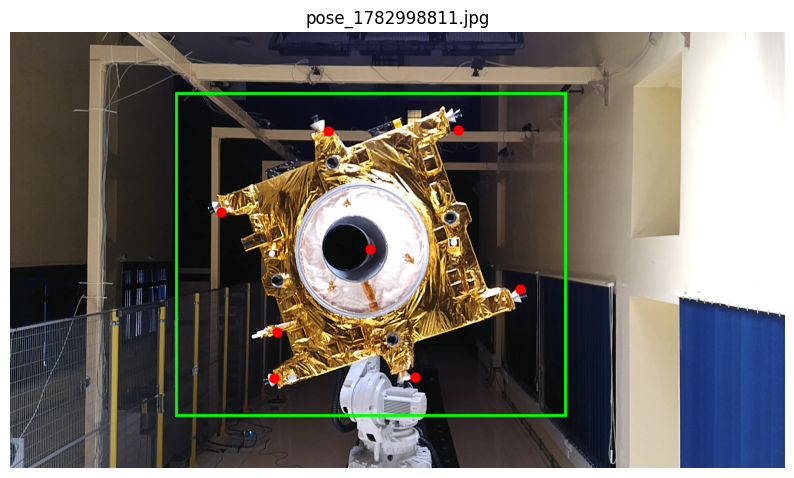

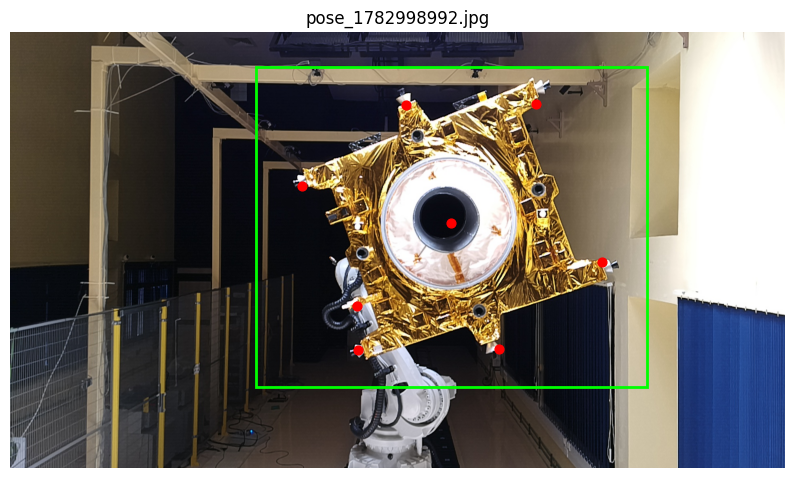

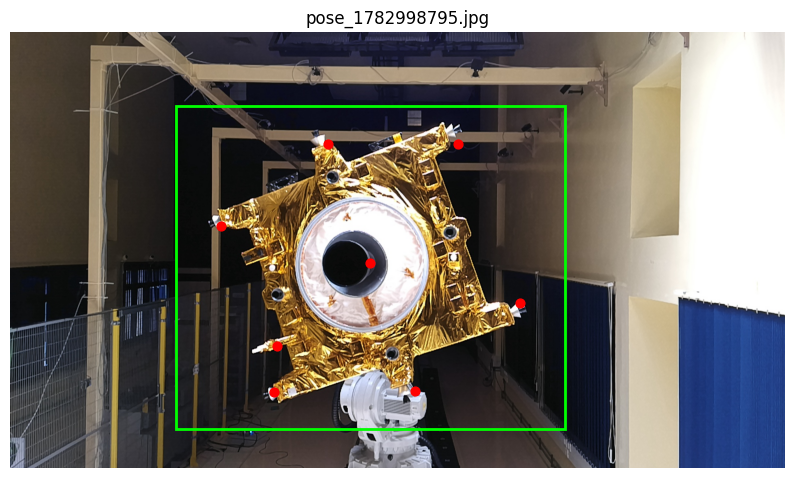

In [5]:
import matplotlib.pyplot as plt

def show_sample(label, captures_dir):
    img = cv2.imread(os.path.join(captures_dir, label['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    kpts = np.array(label['keypoints_2d'])
    x1, y1, x2, y2 = label['bbox']

    plt.figure(figsize=(10, 6))
    plt.imshow(img)
    plt.scatter(kpts[:, 0], kpts[:, 1], c='red', s=40)
    plt.gca().add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor='lime', linewidth=2))
    plt.title(label['image_file'])
    plt.axis('off')
    plt.show()

for lbl in random.sample(labels, min(3, len(labels))):
    show_sample(lbl, CAPTURES_DIR)




## Cell 5 — Dataset class

Produces, per sample: cropped ROI (with padding around the projected bbox, mimicking imperfect Stage-1 detection),
keypoints in crop-normalized `[0,1]` coordinates, and the 6-DoF pose target.


In [6]:
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

CROP_SIZE = 224

class SatellitePoseDataset(Dataset):
    def __init__(self, labels, captures_dir, crop_size=CROP_SIZE, augment=True, bbox_jitter=0.1):
        self.labels = labels
        self.captures_dir = captures_dir
        self.crop_size = crop_size
        self.augment = augment
        self.bbox_jitter = bbox_jitter
        self.normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    def __len__(self):
        return len(self.labels)

    def _jitter_bbox(self, bbox, W, H):
        x1, y1, x2, y2 = bbox
        w, h = x2 - x1, y2 - y1
        if self.augment:
            dx = np.random.uniform(-self.bbox_jitter, self.bbox_jitter) * w
            dy = np.random.uniform(-self.bbox_jitter, self.bbox_jitter) * h
            x1, x2 = x1 + dx, x2 + dx
            y1, y2 = y1 + dy, y2 + dy
        # make square
        w, h = x2 - x1, y2 - y1
        side = max(w, h)
        cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
        x1, x2 = cx - side / 2, cx + side / 2
        y1, y2 = cy - side / 2, cy + side / 2
        x1, y1 = max(0, x1), max(0, y1)
        x2, y2 = min(W, x2), min(H, y2)
        return x1, y1, x2, y2

    def __getitem__(self, idx):
        lbl = self.labels[idx]
        img = cv2.imread(os.path.join(self.captures_dir, lbl['image_file']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = lbl['height'], lbl['width']

        x1, y1, x2, y2 = self._jitter_bbox(lbl['bbox'], W, H)
        crop = img[int(y1):int(y2), int(x1):int(x2)]
        if crop.shape[0] < 2 or crop.shape[1] < 2:
            # degenerate crop fallback
            crop = img
            x1, y1, x2, y2 = 0, 0, W, H

        ch, cw = crop.shape[:2]
        crop_resized = cv2.resize(crop, (self.crop_size, self.crop_size))

        kpts = np.array(lbl['keypoints_2d'], dtype=np.float32)
        kpts_crop = kpts.copy()
        kpts_crop[:, 0] = (kpts_crop[:, 0] - x1) / cw
        kpts_crop[:, 1] = (kpts_crop[:, 1] - y1) / ch
        kpts_crop = np.clip(kpts_crop, -0.5, 1.5)  # allow slight overflow for jittered crops

        img_t = torch.from_numpy(crop_resized).permute(2, 0, 1).float() / 255.0
        img_t = self.normalize(img_t)

        quat = np.array(lbl['rotation_quat_xyzw'], dtype=np.float32)
        trans = np.array(lbl['translation'], dtype=np.float32)

        return {
            'image': img_t,
            'keypoints': torch.from_numpy(kpts_crop),          # (8,2) normalized to crop
            'crop_box': torch.tensor([x1, y1, x2, y2], dtype=torch.float32),  # original-image coords
            'quat': torch.from_numpy(quat),
            'trans': torch.from_numpy(trans),
            'image_file': lbl['image_file'],
        }

# Train / val split
random.seed(42)
shuffled = labels[:]
random.shuffle(shuffled)
n_val = max(1, int(0.1 * len(shuffled)))
val_labels = shuffled[:n_val]
train_labels = shuffled[n_val:]
print(f"Train: {len(train_labels)}  Val: {len(val_labels)}")

train_ds = SatellitePoseDataset(train_labels, CAPTURES_DIR, augment=True)
val_ds = SatellitePoseDataset(val_labels, CAPTURES_DIR, augment=False)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

batch = next(iter(train_loader))
print({k: (v.shape if torch.is_tensor(v) else type(v)) for k, v in batch.items()})


Train: 25  Val: 2
{'image': torch.Size([16, 3, 224, 224]), 'keypoints': torch.Size([16, 8, 2]), 'crop_box': torch.Size([16, 4]), 'quat': torch.Size([16, 4]), 'trans': torch.Size([16, 3]), 'image_file': <class 'list'>}


## Stage 1 — Segmentation + ROI crop

Real silhouette masks don't exist, so we generate weak supervision masks as the convex hull of the projected
keypoints (a reasonable silhouette proxy for a rigid, mostly-convex satellite body). A lightweight U-Net-style
head learns to predict this mask on the full frame; at inference the mask's bounding box becomes the ROI for Stage 2.


In [7]:
import torch.nn as nn
import torch.nn.functional as F

def hull_mask_from_keypoints(kpts_2d, W, H, out_size=128):
    mask = np.zeros((H, W), dtype=np.uint8)
    pts = kpts_2d.astype(np.int32)
    hull = cv2.convexHull(pts)
    cv2.fillConvexPoly(mask, hull, 1)
    mask_small = cv2.resize(mask, (out_size, out_size), interpolation=cv2.INTER_NEAREST)
    return mask_small

class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.net(x)

class SegNet(nn.Module):
    """Small U-Net. Input: full frame downsized to 256x256. Output: 128x128 mask logits."""
    def __init__(self):
        super().__init__()
        self.enc1 = ConvBlock(3, 16)
        self.enc2 = ConvBlock(16, 32)
        self.enc3 = ConvBlock(32, 64)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = ConvBlock(64, 128)
        self.up2 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec2 = ConvBlock(128, 64)
        self.up1 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.dec1 = ConvBlock(64, 32)
        self.out_conv = nn.Conv2d(32, 1, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        b = self.bottleneck(self.pool(e3))
        d2 = self.dec2(torch.cat([self.up2(b), e3], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e2], dim=1))
        out = self.out_conv(d1)  # 1/4 resolution mask logits
        return out

def mask_to_bbox(mask_prob, W, H, thresh=0.5, pad_frac=0.15):
    mask_bin = (mask_prob > thresh).astype(np.uint8)
    ys, xs = np.where(mask_bin)
    if len(xs) == 0:
        return [0, 0, W, H]
    x1, x2 = xs.min() / mask_prob.shape[1] * W, xs.max() / mask_prob.shape[1] * W
    y1, y2 = ys.min() / mask_prob.shape[0] * H, ys.max() / mask_prob.shape[0] * H
    w, h = x2 - x1, y2 - y1
    x1 -= w * pad_frac; x2 += w * pad_frac
    y1 -= h * pad_frac; y2 += h * pad_frac
    return [max(0, x1), max(0, y1), min(W, x2), min(H, y2)]

print("Stage 1 (SegNet) defined.")


Stage 1 (SegNet) defined.


### Stage 1 dataset + training

Trains the segmentation head separately on full frames (256x256) against the convex-hull pseudo-masks.


In [8]:
class SegDataset(Dataset):
    def __init__(self, labels, captures_dir, in_size=256, mask_size=128):
        self.labels = labels
        self.captures_dir = captures_dir
        self.in_size = in_size
        self.mask_size = mask_size

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        lbl = self.labels[idx]
        img = cv2.imread(os.path.join(self.captures_dir, lbl['image_file']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = lbl['height'], lbl['width']
        kpts = np.array(lbl['keypoints_2d'], dtype=np.float32)

        mask = hull_mask_from_keypoints(kpts, W, H, out_size=self.mask_size)
        img_resized = cv2.resize(img, (self.in_size, self.in_size))

        img_t = torch.from_numpy(img_resized).permute(2, 0, 1).float() / 255.0
        mask_t = torch.from_numpy(mask).float().unsqueeze(0)
        return img_t, mask_t

seg_train_ds = SegDataset(train_labels, CAPTURES_DIR)
seg_val_ds = SegDataset(val_labels, CAPTURES_DIR)
seg_train_loader = DataLoader(seg_train_ds, batch_size=16, shuffle=True, num_workers=2)
seg_val_loader = DataLoader(seg_val_ds, batch_size=16, shuffle=False, num_workers=2)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
seg_model = SegNet().to(device)
seg_opt = torch.optim.Adam(seg_model.parameters(), lr=1e-3)
seg_criterion = nn.BCEWithLogitsLoss()

SEG_EPOCHS = 15
for epoch in range(SEG_EPOCHS):
    seg_model.train()
    total_loss = 0
    for img_t, mask_t in seg_train_loader:
        img_t, mask_t = img_t.to(device), mask_t.to(device)
        seg_opt.zero_grad()
        logits = seg_model(img_t)
        loss = seg_criterion(logits, mask_t)
        loss.backward()
        seg_opt.step()
        total_loss += loss.item()

    seg_model.eval()
    val_loss = 0
    with torch.no_grad():
        for img_t, mask_t in seg_val_loader:
            img_t, mask_t = img_t.to(device), mask_t.to(device)
            logits = seg_model(img_t)
            val_loss += seg_criterion(logits, mask_t).item()

    print(f"[Seg] Epoch {epoch+1}/{SEG_EPOCHS}  train_loss={total_loss/len(seg_train_loader):.4f}  val_loss={val_loss/max(1,len(seg_val_loader)):.4f}")

os.makedirs('/content/checkpoints', exist_ok=True)
torch.save(seg_model.state_dict(), '/content/checkpoints/seg_model.pt')
print("Saved Stage 1 segmentation model.")


[Seg] Epoch 1/15  train_loss=0.5759  val_loss=0.6510
[Seg] Epoch 2/15  train_loss=0.4285  val_loss=0.6276
[Seg] Epoch 3/15  train_loss=0.3724  val_loss=0.5947
[Seg] Epoch 4/15  train_loss=0.3435  val_loss=0.5648
[Seg] Epoch 5/15  train_loss=0.3281  val_loss=0.5420
[Seg] Epoch 6/15  train_loss=0.3157  val_loss=0.5249
[Seg] Epoch 7/15  train_loss=0.3048  val_loss=0.5120
[Seg] Epoch 8/15  train_loss=0.2948  val_loss=0.5019
[Seg] Epoch 9/15  train_loss=0.2864  val_loss=0.4914
[Seg] Epoch 10/15  train_loss=0.2790  val_loss=0.4810
[Seg] Epoch 11/15  train_loss=0.2718  val_loss=0.4728
[Seg] Epoch 12/15  train_loss=0.2644  val_loss=0.4675
[Seg] Epoch 13/15  train_loss=0.2573  val_loss=0.4648
[Seg] Epoch 14/15  train_loss=0.2504  val_loss=0.4643
[Seg] Epoch 15/15  train_loss=0.2441  val_loss=0.4653
Saved Stage 1 segmentation model.


## Stage 2 — ViT keypoint regression with uncertainty

Heatmap-free: a ViT backbone (via `timm`) regresses `(u, v, log_sigma)` per keypoint directly from the cropped ROI.
Trained with a Gaussian negative-log-likelihood loss (Kendall & Gal style), so the network learns to output
larger `sigma` for keypoints it's unsure about (occluded, foreshortened, etc.) — this uncertainty feeds Stage 3's
confidence weighting and Stage 5's measurement noise.


In [9]:
import timm

class ViTKeypointRegressor(nn.Module):
    def __init__(self, num_keypoints=NUM_KEYPOINTS, backbone='vit_small_patch16_224', pretrained=True):
        super().__init__()
        self.backbone = timm.create_model(backbone, pretrained=pretrained, num_classes=0)
        feat_dim = self.backbone.num_features
        self.head = nn.Sequential(
            nn.Linear(feat_dim, 256), nn.ReLU(inplace=True),
            nn.Linear(256, num_keypoints * 3)  # (u, v, log_sigma) per keypoint
        )
        self.num_keypoints = num_keypoints

    def forward(self, x):
        feat = self.backbone(x)
        out = self.head(feat)
        out = out.view(-1, self.num_keypoints, 3)
        uv = torch.sigmoid(out[..., :2])          # normalized crop coords in [0,1]
        log_sigma = out[..., 2]                    # unconstrained
        return uv, log_sigma

def gaussian_nll_loss(pred_uv, log_sigma, target_uv, eps=1e-6):
    sigma = torch.exp(log_sigma) + eps
    sq_err = ((pred_uv - target_uv) ** 2).sum(dim=-1)  # (B, K)
    nll = 0.5 * sq_err / (sigma ** 2) + torch.log(sigma)
    return nll.mean()

kp_model = ViTKeypointRegressor().to(device)
print(sum(p.numel() for p in kp_model.parameters()) / 1e6, "M params")


model.safetensors:   0%|          | 0.00/88.2M [00:00<?, ?B/s]

21.770392 M params


In [10]:
kp_opt = torch.optim.AdamW(kp_model.parameters(), lr=1e-4, weight_decay=1e-4)
kp_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(kp_opt, T_max=30)

KP_EPOCHS = 30
best_val = float('inf')

for epoch in range(KP_EPOCHS):
    kp_model.train()
    total_loss = 0
    for batch in train_loader:
        img = batch['image'].to(device)
        target_kpts = batch['keypoints'].to(device)

        kp_opt.zero_grad()
        pred_uv, log_sigma = kp_model(img)
        loss = gaussian_nll_loss(pred_uv, log_sigma, target_kpts)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(kp_model.parameters(), 1.0)
        kp_opt.step()
        total_loss += loss.item()

    kp_scheduler.step()

    kp_model.eval()
    val_loss = 0
    px_err = 0
    with torch.no_grad():
        for batch in val_loader:
            img = batch['image'].to(device)
            target_kpts = batch['keypoints'].to(device)
            pred_uv, log_sigma = kp_model(img)
            val_loss += gaussian_nll_loss(pred_uv, log_sigma, target_kpts).item()
            px_err += (((pred_uv - target_kpts) * CROP_SIZE) ** 2).sum(-1).sqrt().mean().item()

    avg_val = val_loss / max(1, len(val_loader))
    avg_px_err = px_err / max(1, len(val_loader))
    print(f"[KP] Epoch {epoch+1}/{KP_EPOCHS}  train_nll={total_loss/len(train_loader):.4f}  val_nll={avg_val:.4f}  val_pixel_err={avg_px_err:.2f}px")

    if avg_val < best_val:
        best_val = avg_val
        torch.save(kp_model.state_dict(), '/content/checkpoints/kp_model_best.pt')

print("Saved Stage 2 best keypoint model.")


[KP] Epoch 1/30  train_nll=0.1805  val_nll=-0.3642  val_pixel_err=75.52px
[KP] Epoch 2/30  train_nll=-0.2882  val_nll=-0.4534  val_pixel_err=67.93px
[KP] Epoch 3/30  train_nll=-0.4676  val_nll=-0.7119  val_pixel_err=56.05px
[KP] Epoch 4/30  train_nll=-0.7031  val_nll=-1.0062  val_pixel_err=47.35px
[KP] Epoch 5/30  train_nll=-0.9546  val_nll=-1.2015  val_pixel_err=45.15px
[KP] Epoch 6/30  train_nll=-1.0818  val_nll=-1.3351  val_pixel_err=40.94px
[KP] Epoch 7/30  train_nll=-1.2043  val_nll=-1.4629  val_pixel_err=35.90px
[KP] Epoch 8/30  train_nll=-1.2926  val_nll=-1.5351  val_pixel_err=30.46px
[KP] Epoch 9/30  train_nll=-1.4024  val_nll=-1.6163  val_pixel_err=26.81px
[KP] Epoch 10/30  train_nll=-1.5150  val_nll=-1.7089  val_pixel_err=24.08px
[KP] Epoch 11/30  train_nll=-1.5591  val_nll=-1.8310  val_pixel_err=22.19px
[KP] Epoch 12/30  train_nll=-1.6802  val_nll=-1.9249  val_pixel_err=18.66px
[KP] Epoch 13/30  train_nll=-1.7047  val_nll=-1.8995  val_pixel_err=18.21px
[KP] Epoch 14/30  trai

## Stage 3 — Confidence-weighted RANSAC-EPnP

Maps predicted crop-normalized keypoints back into full-image pixel coordinates using the crop box, drops
low-confidence (high-sigma) correspondences, then solves 6-DoF pose with `cv2.solvePnPRansac` (EPnP).


In [64]:
def predicted_kpts_to_image_coords(pred_uv, crop_box):
    """pred_uv: (K,2) in [0,1] crop-normalized. crop_box: (x1,y1,x2,y2) in original image."""
    x1, y1, x2, y2 = crop_box
    w, h = x2 - x1, y2 - y1
    img_pts = pred_uv.copy()
    img_pts[:, 0] = img_pts[:, 0] * w + x1
    img_pts[:, 1] = img_pts[:, 1] * h + y1
    return img_pts

def confidence_weighted_epnp(pred_uv, log_sigma, crop_box, sigma_thresh=0.005, min_points=4):
    """
    pred_uv: (K,2) normalized crop coords (numpy)
    log_sigma: (K,) numpy
    crop_box: (4,) numpy
    Returns: rot_mat (3,3), tvec (3,), inlier_mask (K,) bool, success (bool)
    """
    sigma = np.exp(log_sigma)
    keep = sigma < sigma_thresh
    if keep.sum() < min_points:
        # relax: keep the most confident min_points
        order = np.argsort(sigma)
        keep = np.zeros_like(keep)
        keep[order[:min_points]] = True

    img_pts = predicted_kpts_to_image_coords(pred_uv, crop_box)
    obj_pts = POINTS_3D[keep].astype(np.float32)
    img_pts_kept = img_pts[keep].astype(np.float32)

    if obj_pts.shape[0] < 4:
        return None, None, keep, False

    success, rvec, tvec, inliers = cv2.solvePnPRansac(
        obj_pts, img_pts_kept, K, DIST_COEFF,
        flags=cv2.SOLVEPNP_EPNP,
        reprojectionError=8.0,
        confidence=0.99,
        iterationsCount=200,
    )
    if not success:
        return None, None, keep, False

    # refine with Levenberg-Marquardt on inliers only
    if inliers is not None and len(inliers) >= 4:
        rvec, tvec = cv2.solvePnPRefineLM(
            obj_pts[inliers.flatten()], img_pts_kept[inliers.flatten()], K, DIST_COEFF, rvec, tvec
        )

    rot_mat, _ = cv2.Rodrigues(rvec)
    return rot_mat, tvec.reshape(-1), keep, True

print("Stage 3 (confidence-weighted RANSAC-EPnP) defined.")


Stage 3 (confidence-weighted RANSAC-EPnP) defined.


## Full Stage 1→3 inference function + evaluation (ADD, rotation & translation error)

Runs segmentation → crop → keypoint regression → EPnP end-to-end on a raw image, and compares against ground truth.


In [66]:
def run_full_pipeline(img_rgb, seg_model, kp_model, device, seg_in_size=256, seg_out_size=128, crop_size=CROP_SIZE):
    H, W = img_rgb.shape[:2]

    # Stage 1
    seg_model.eval()
    seg_input = cv2.resize(img_rgb, (seg_in_size, seg_in_size))
    seg_t = torch.from_numpy(seg_input).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255.0
    with torch.no_grad():
        mask_logits = seg_model(seg_t)
        mask_prob = torch.sigmoid(mask_logits)[0, 0].cpu().numpy()
    bbox = mask_to_bbox(mask_prob, W, H)

    x1, y1, x2, y2 = bbox
    side = max(x2 - x1, y2 - y1)
    cx, cy = (x1 + x2) / 2, (y1 + y2) / 2
    x1, x2 = cx - side / 2, cx + side / 2
    y1, y2 = cy - side / 2, cy + side / 2
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(W, x2), min(H, y2)
    crop_box = np.array([x1, y1, x2, y2])

    crop = img_rgb[int(y1):int(y2), int(x1):int(x2)]
    if crop.shape[0] < 2 or crop.shape[1] < 2:
        return None

    crop_resized = cv2.resize(crop, (crop_size, crop_size))
    normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    crop_t = torch.from_numpy(crop_resized).permute(2, 0, 1).float() / 255.0
    crop_t = normalize(crop_t).unsqueeze(0).to(device)

    # Stage 2
    kp_model.eval()
    with torch.no_grad():
        pred_uv, log_sigma = kp_model(crop_t)
    pred_uv = pred_uv[0].cpu().numpy()
    log_sigma = log_sigma[0].cpu().numpy()

    # Stage 3
    rot_mat, tvec, keep_mask, success = confidence_weighted_epnp(pred_uv, log_sigma, crop_box)

    return {
        'bbox': bbox, 'crop_box': crop_box, 'pred_uv': pred_uv, 'log_sigma': log_sigma,
        'rot_mat': rot_mat, 'tvec': tvec, 'inlier_mask': keep_mask, 'success': success,
    }

def add_metric(rot_pred, t_pred, rot_gt, t_gt, points_3d=POINTS_3D):
    pred_pts = (rot_pred @ points_3d.T).T + t_pred
    gt_pts = (rot_gt @ points_3d.T).T + t_gt
    return np.linalg.norm(pred_pts - gt_pts, axis=1).mean()

def rotation_error_deg(rot_pred, rot_gt):
    R_diff = rot_pred @ rot_gt.T
    trace = np.clip((np.trace(R_diff) - 1) / 2, -1, 1)
    return np.degrees(np.arccos(trace))

def translation_error(t_pred, t_gt):
    return np.linalg.norm(t_pred - t_gt)

# --- Evaluate on validation set ---
add_errors, rot_errors, trans_errors, n_fail = [], [], [], 0
for lbl in val_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is None or not result['success']:
        n_fail += 1
        continue

    rot_gt, _ = camera_location_to_pose  # placeholder to avoid accidental shadow; not used directly
    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    t_gt = np.array(lbl['translation'])

    add_errors.append(add_metric(result['rot_mat'], result['tvec'], rot_gt, t_gt))
    rot_errors.append(rotation_error_deg(result['rot_mat'], rot_gt))
    trans_errors.append(translation_error(result['tvec'], t_gt))

print(f"Evaluated {len(add_errors)}/{len(val_labels)} samples ({n_fail} PnP failures)")
if add_errors:
    print(f"ADD (mean):        {np.mean(add_errors):.4f} m")
    print(f"Rotation err (mean): {np.mean(rot_errors):.2f} deg")
    print(f"Translation err (mean): {np.mean(trans_errors):.4f} m")


TypeError: cannot unpack non-iterable function object

## Stage 4 — Uncertainty-gated self-training (optional)

Your current dataset is fully labeled via reprojection, so this stage isn't strictly needed to train Stage 1-3.
It becomes useful if you later add **unlabeled real images** (no `camera_location` available — e.g. from onboard
flight cameras rather than the lab rig) and want to adapt the ViT keypoint model to that new domain without ground truth.

The loop: run current Stage 1-3 on unlabeled images → keep only PnP-refined poses whose reprojected keypoints have
low predicted sigma (high confidence) → treat those refined 2D positions as pseudo-labels → fine-tune Stage 2 on them.


In [13]:
def self_train_on_unlabeled(unlabeled_image_paths, seg_model, kp_model, device,
                             sigma_thresh=0.08, epochs=5, lr=1e-5, reproj_error_thresh=3.0):
    kp_model.train()
    opt = torch.optim.AdamW(kp_model.parameters(), lr=lr)
    normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

    pseudo_samples = []
    for path in unlabeled_image_paths:
        img = cv2.imread(path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        result = run_full_pipeline(img, seg_model, kp_model, device)
        if result is None or not result['success']:
            continue

        # reproject refined pose and check agreement with the raw regressed keypoints
        img_pts_refined, _ = cv2.projectPoints(POINTS_3D, result['rot_mat'], result['tvec'], K, DIST_COEFF)
        img_pts_refined = np.abs(img_pts_refined.reshape(-1, 2))

        crop_box = result['crop_box']
        pred_img_pts = predicted_kpts_to_image_coords(result['pred_uv'], crop_box)
        reproj_err = np.linalg.norm(img_pts_refined - pred_img_pts, axis=1)
        sigma = np.exp(result['log_sigma'])

        confident = (sigma < sigma_thresh) & (reproj_err < reproj_error_thresh)
        if confident.sum() < 4:
            continue

        x1, y1, x2, y2 = crop_box
        w, h = x2 - x1, y2 - y1
        kpts_crop_target = result['pred_uv'].copy()
        kpts_crop_target[confident, 0] = (img_pts_refined[confident, 0] - x1) / w
        kpts_crop_target[confident, 1] = (img_pts_refined[confident, 1] - y1) / h

        pseudo_samples.append((path, crop_box, kpts_crop_target, confident))

    print(f"Collected {len(pseudo_samples)} confident pseudo-labeled frames out of {len(unlabeled_image_paths)}")

    for epoch in range(epochs):
        total_loss = 0
        for path, crop_box, target_kpts, confident in pseudo_samples:
            img = cv2.imread(path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            x1, y1, x2, y2 = crop_box
            crop = img[int(y1):int(y2), int(x1):int(x2)]
            if crop.shape[0] < 2 or crop.shape[1] < 2:
                continue
            crop_resized = cv2.resize(crop, (CROP_SIZE, CROP_SIZE))
            crop_t = torch.from_numpy(crop_resized).permute(2, 0, 1).float() / 255.0
            crop_t = normalize(crop_t).unsqueeze(0).to(device)

            target_t = torch.from_numpy(target_kpts).float().unsqueeze(0).to(device)
            mask_t = torch.from_numpy(confident).unsqueeze(0).to(device)

            opt.zero_grad()
            pred_uv, log_sigma = kp_model(crop_t)
            loss = gaussian_nll_loss(pred_uv[mask_t.unsqueeze(-1).expand_as(pred_uv)].view(1, -1, 2),
                                      log_sigma[mask_t].view(1, -1),
                                      target_t[mask_t.unsqueeze(-1).expand_as(target_t)].view(1, -1, 2))
            loss.backward()
            opt.step()
            total_loss += loss.item()

        print(f"[Self-train] Epoch {epoch+1}/{epochs}  loss={total_loss/max(1,len(pseudo_samples)):.4f}")

    torch.save(kp_model.state_dict(), '/content/checkpoints/kp_model_selftrained.pt')
    return kp_model

# Example usage (only run if you actually have unlabeled images somewhere):
# unlabeled_paths = glob.glob('/content/dataset/unlabeled_real/*.jpg')
# kp_model = self_train_on_unlabeled(unlabeled_paths, seg_model, kp_model, device)
print("Stage 4 defined (call self_train_on_unlabeled(...) if/when you have unlabeled real images).")


Stage 4 defined (call self_train_on_unlabeled(...) if/when you have unlabeled real images).


## Stage 5 — Adaptive Unscented Kalman Filter (temporal fusion)

Fuses a time-ordered sequence of Stage-3 poses into a smoothed trajectory. State = `[x,y,z, qx,qy,qz,qw, vx,vy,vz]`
(constant-velocity translation model, quaternion held with small process noise). Measurement noise `R(t)` is scaled
by the mean keypoint uncertainty (sigma) of that frame's inliers — low-confidence frames get down-weighted automatically.


In [14]:
from filterpy.kalman import UnscentedKalmanFilter, MerweScaledSigmaPoints

STATE_DIM = 10  # x,y,z,qx,qy,qz,qw,vx,vy,vz
MEAS_DIM = 7    # x,y,z,qx,qy,qz,qw

def fx(state, dt):
    x, y, z, qx, qy, qz, qw, vx, vy, vz = state
    x, y, z = x + vx * dt, y + vy * dt, z + vz * dt
    q = np.array([qx, qy, qz, qw])
    q = q / (np.linalg.norm(q) + 1e-8)
    return np.array([x, y, z, *q, vx, vy, vz])

def hx(state):
    return state[:7]

def build_ukf(dt=1.0, process_noise_pos=1e-4, process_noise_quat=1e-5, process_noise_vel=1e-3):
    points = MerweScaledSigmaPoints(n=STATE_DIM, alpha=0.1, beta=2.0, kappa=0.0)
    ukf = UnscentedKalmanFilter(dim_x=STATE_DIM, dim_z=MEAS_DIM, dt=dt, fx=fx, hx=hx, points=points)
    ukf.Q = np.diag([process_noise_pos]*3 + [process_noise_quat]*4 + [process_noise_vel]*3)
    return ukf

def run_ukf_sequence(pose_sequence):
    """
    pose_sequence: list of dicts, time-ordered, each with:
        'timestamp_ms', 'rot_mat' (3,3) or None, 'tvec' (3,) or None,
        'mean_sigma' (float, from Stage 2 inlier keypoints) - used to scale measurement noise.
    Returns: list of smoothed {'trans','quat','cov'} per frame.
    """
    valid = [p for p in pose_sequence if p['rot_mat'] is not None]
    if not valid:
        return []

    first = valid[0]
    quat0 = Rot.from_matrix(first['rot_mat']).as_quat()
    ukf = build_ukf()
    ukf.x = np.array([*first['tvec'], *quat0, 0, 0, 0])
    ukf.P *= 0.1

    results = []
    prev_t = first['timestamp_ms']
    base_meas_noise = np.diag([1e-3]*3 + [1e-3]*4)

    for p in pose_sequence:
        dt = max(1e-3, (p['timestamp_ms'] - prev_t) / 1000.0) if p['timestamp_ms'] else 1.0
        prev_t = p['timestamp_ms'] if p['timestamp_ms'] else prev_t
        ukf.predict(dt=dt)

        if p['rot_mat'] is not None:
            quat = Rot.from_matrix(p['rot_mat']).as_quat()
            z = np.array([*p['tvec'], *quat])
            # Adaptive measurement noise: scale by this frame's mean keypoint uncertainty
            conf_scale = max(p.get('mean_sigma', 0.05), 1e-3)
            ukf.R = base_meas_noise * (conf_scale / 0.05)
            ukf.update(z)

        state = ukf.x.copy()
        q = state[3:7]
        q = q / (np.linalg.norm(q) + 1e-8)
        results.append({
            'trans': state[:3].copy(),
            'quat': q,
            'cov': ukf.P.copy(),
        })

    return results

print("Stage 5 (Adaptive UKF) defined.")


Stage 5 (Adaptive UKF) defined.


### Example: run Stage 1→5 end-to-end over a time-ordered sequence of validation frames

In [15]:
seq_labels = sorted(val_labels, key=lambda l: l['timestamp_ms'] if l['timestamp_ms'] else 0)

pose_sequence = []
for lbl in seq_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)

    if result is not None and result['success']:
        mean_sigma = float(np.exp(result['log_sigma'][result['inlier_mask']]).mean())
        pose_sequence.append({
            'timestamp_ms': lbl['timestamp_ms'],
            'rot_mat': result['rot_mat'],
            'tvec': result['tvec'],
            'mean_sigma': mean_sigma,
        })
    else:
        pose_sequence.append({'timestamp_ms': lbl['timestamp_ms'], 'rot_mat': None, 'tvec': None, 'mean_sigma': None})

smoothed = run_ukf_sequence(pose_sequence)
print(f"Smoothed {len(smoothed)} frames.")
if smoothed:
    print("First smoothed pose - trans:", smoothed[0]['trans'], " quat:", smoothed[0]['quat'])
    print("Last  smoothed pose - trans:", smoothed[-1]['trans'], " quat:", smoothed[-1]['quat'])


Smoothed 0 frames.


new

In [16]:
import cv2
import numpy as np
import json
import os

def get_bbox_for_frame(json_path, pad_frac=0.15):
    with open(json_path) as f:
        data = json.load(f)

    img_path = os.path.splitext(json_path)[0] + '.jpg'
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    W, H = data['resolution']['width'], data['resolution']['height']

    cam_loc = data['camera_location']
    rot_mat, tvec = camera_location_to_pose(cam_loc)
    kpts_raw, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, DIST_COEFF)
    kpts_2d = np.abs(kpts_raw.reshape(-1, 2))

    x1, y1 = kpts_2d[:, 0].min(), kpts_2d[:, 1].min()
    x2, y2 = kpts_2d[:, 0].max(), kpts_2d[:, 1].max()
    w, h = x2 - x1, y2 - y1
    x1 -= w * pad_frac; x2 += w * pad_frac
    y1 -= h * pad_frac; y2 += h * pad_frac
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(W, x2), min(H, y2)

    return img, kpts_2d, (x1, y1, x2, y2)

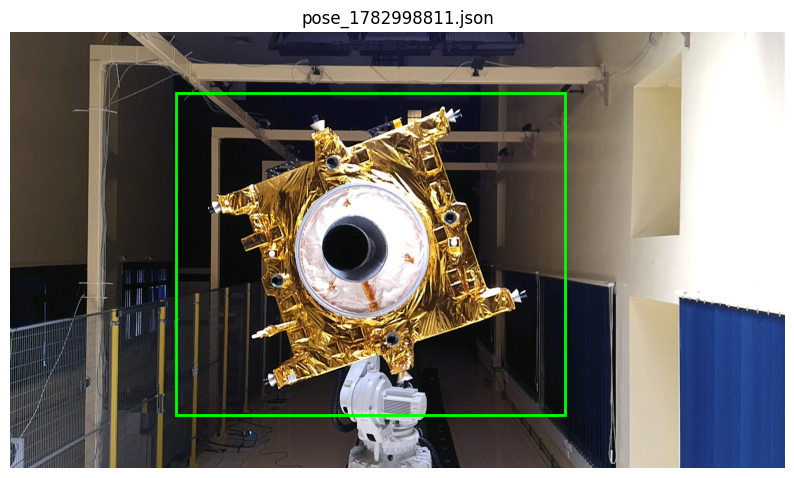

In [17]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show_bbox(json_path):
    img, kpts_2d, (x1, y1, x2, y2) = get_bbox_for_frame(json_path)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(img)


    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                              linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(os.path.basename(json_path))
    ax.axis('off')
    plt.show()


show_bbox(os.path.join(CAPTURES_DIR, 'pose_1782998811.json'))

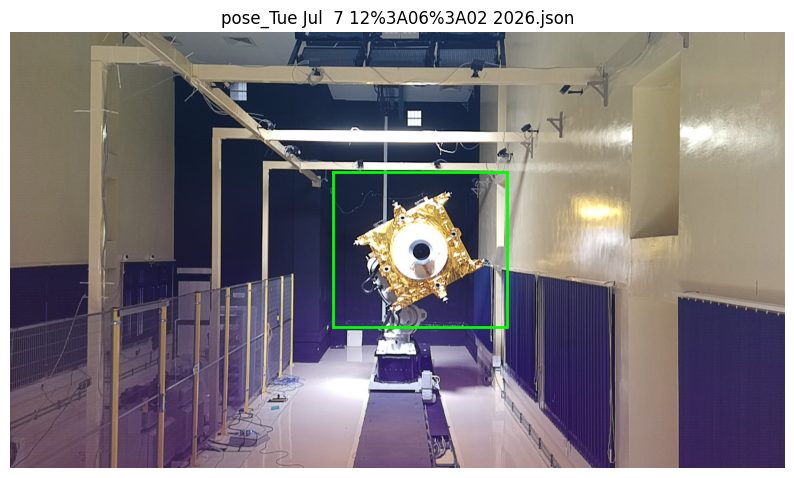

In [18]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show_bbox(json_path):
    img, kpts_2d, (x1, y1, x2, y2) = get_bbox_for_frame(json_path)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(img)
    ax.scatter
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                              linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(os.path.basename(json_path))
    ax.axis('off')
    plt.show()


show_bbox(os.path.join(CAPTURES_DIR, 'pose_Tue Jul  7 12%3A06%3A02 2026.json'))

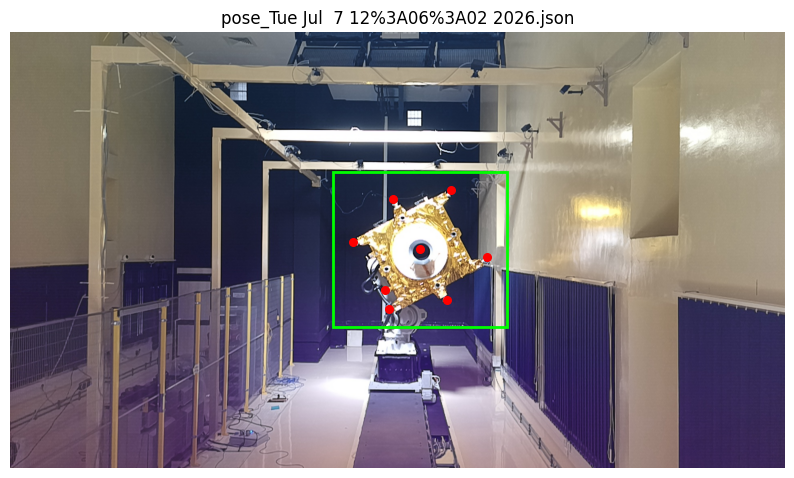

In [19]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show_bbox(json_path):
    img, kpts_2d, (x1, y1, x2, y2) = get_bbox_for_frame(json_path)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(img)
    ax.scatter(kpts_2d[:, 0], kpts_2d[:, 1], c='red', s=30)
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                              linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(os.path.basename(json_path))
    ax.axis('off')
    plt.show()


show_bbox(os.path.join(CAPTURES_DIR, 'pose_Tue Jul  7 12%3A06%3A02 2026.json'))

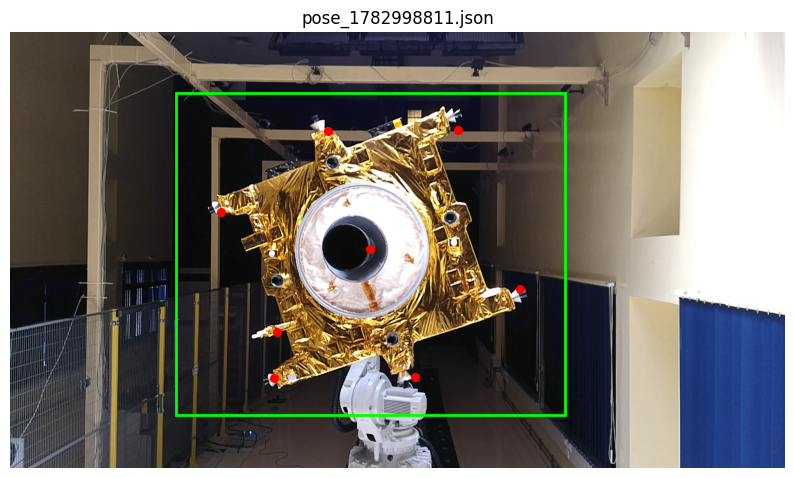

In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def show_bbox(json_path):
    img, kpts_2d, (x1, y1, x2, y2) = get_bbox_for_frame(json_path)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(img)
    ax.scatter(kpts_2d[:, 0], kpts_2d[:, 1], c='red', s=30)
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                              linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(os.path.basename(json_path))
    ax.axis('off')
    plt.show()


show_bbox(os.path.join(CAPTURES_DIR, 'pose_1782998811.json'))

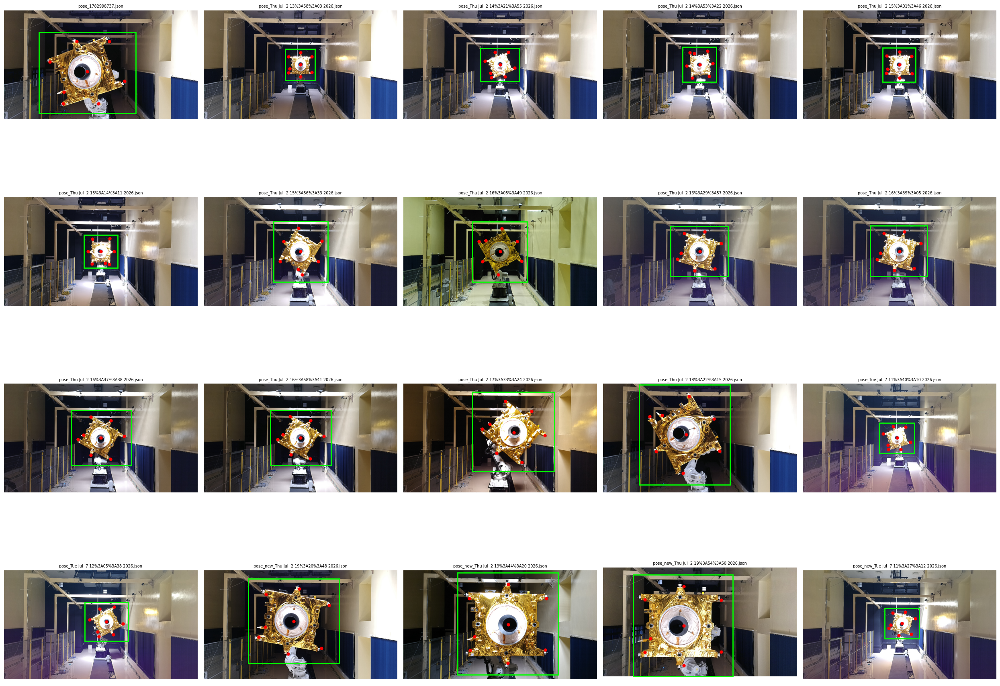

In [21]:
import glob

json_files = sorted(glob.glob(os.path.join(CAPTURES_DIR, 'pose_*.json')))
idxs = np.linspace(0, len(json_files) - 1, 20).astype(int)
sample_files = [json_files[i] for i in idxs]

fig, axes = plt.subplots(4, 5, figsize=(25, 20))
axes = axes.flatten()

for ax, jp in zip(axes, sample_files):
    img, kpts_2d, (x1, y1, x2, y2) = get_bbox_for_frame(jp)
    ax.imshow(img)
    ax.scatter(kpts_2d[:, 0], kpts_2d[:, 1], c='red', s=25)
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                              linewidth=2, edgecolor='lime', facecolor='none')
    ax.add_patch(rect)
    ax.set_title(os.path.basename(jp), fontsize=7)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/bbox_grid.png', dpi=100)
plt.show()

Total frames: 983
Area ratio stats: min=0.0197 max=0.3653 median=0.0810


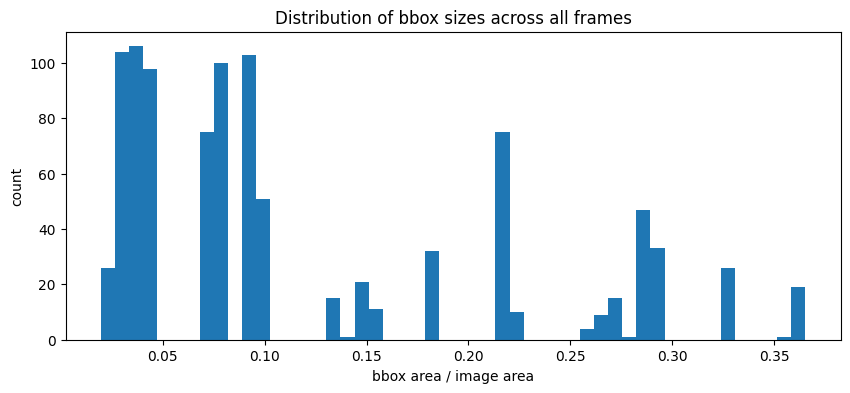


Flagged as BAD (area_ratio < 0.02): 8
Flagged as GOOD: 975

--- First 10 bad frames (check if they cluster in time) ---
pose_Thu Jul  2 13%3A48%3A47 2026.jpg area_ratio= 0.0197 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, -10.0, 0.0]
pose_Thu Jul  2 13%3A49%3A04 2026.jpg area_ratio= 0.0198 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, -8.0, 0.0]
pose_Thu Jul  2 13%3A49%3A13 2026.jpg area_ratio= 0.0199 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, -6.0, 0.0]
pose_Thu Jul  2 13%3A49%3A22 2026.jpg area_ratio= 0.02 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, -4.0, 0.0]
pose_Thu Jul  2 13%3A50%3A02 2026.jpg area_ratio= 0.02 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, 4.0, 0.0]
pose_Thu Jul  2 13%3A50%3A09 2026.jpg area_ratio= 0.0199 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, 6.0, 0.0]
pose_Thu Jul  2 13%3A50%3A17 2026.jpg area_ratio= 0.0199 cam_loc= [0.0, 14.635000228881836, 0.0, 0.0, 8.0, 0.0]
pose_Thu Jul  2 13%3A50%3A22 2026.jpg area_ratio= 0.0198 cam_loc= [0.0, 14.635000228881836, 0.

In [22]:
import glob, json, os
import numpy as np
import cv2

json_files = sorted(glob.glob(os.path.join(CAPTURES_DIR, 'pose_*.json')))

records = []
for jp in json_files:
    with open(jp) as f:
        data = json.load(f)
    img_path = os.path.splitext(jp)[0] + '.jpg'
    if not os.path.exists(img_path):
        continue

    W, H = data['resolution']['width'], data['resolution']['height']
    cam_loc = data['camera_location']
    rot_mat, tvec = camera_location_to_pose(cam_loc)
    kpts_raw, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, DIST_COEFF)
    kpts_2d = np.abs(kpts_raw.reshape(-1, 2))

    x1, y1 = kpts_2d[:, 0].min(), kpts_2d[:, 1].min()
    x2, y2 = kpts_2d[:, 0].max(), kpts_2d[:, 1].max()
    box_area = max(0, x2 - x1) * max(0, y2 - y1)
    area_ratio = box_area / (W * H)

    records.append({
        'file': os.path.basename(img_path),
        'timestamp_ms': data.get('timestamp_ms'),
        'area_ratio': area_ratio,
        'cam_loc': cam_loc,
    })

area_ratios = np.array([r['area_ratio'] for r in records])
print(f"Total frames: {len(records)}")
print(f"Area ratio stats: min={area_ratios.min():.4f} max={area_ratios.max():.4f} "
      f"median={np.median(area_ratios):.4f}")

import matplotlib.pyplot as plt
plt.figure(figsize=(10,4))
plt.hist(area_ratios, bins=50)
plt.xlabel("bbox area / image area")
plt.ylabel("count")
plt.title("Distribution of bbox sizes across all frames")
plt.savefig('/content/area_ratio_hist.png', dpi=100)
plt.show()

# Flag likely-bad frames as clear outliers on the small end
THRESH = 0.02  # start here, adjust after looking at the histogram
bad = [r for r in records if r['area_ratio'] < THRESH]
good = [r for r in records if r['area_ratio'] >= THRESH]
print(f"\nFlagged as BAD (area_ratio < {THRESH}): {len(bad)}")
print(f"Flagged as GOOD: {len(good)}")

print("\n--- First 10 bad frames (check if they cluster in time) ---")
for r in bad[:10]:
    print(r['file'], "area_ratio=", round(r['area_ratio'], 4), "cam_loc=", r['cam_loc'])

print("\n--- Last 10 bad frames ---")
for r in bad[-10:]:
    print(r['file'], "area_ratio=", round(r['area_ratio'], 4), "cam_loc=", r['cam_loc'])

In [23]:
def bbox_from_keypoints(kpts_2d, img_w, img_h, pad_frac=0.15):
    x1, y1 = kpts_2d[:, 0].min(), kpts_2d[:, 1].min()
    x2, y2 = kpts_2d[:, 0].max(), kpts_2d[:, 1].max()
    w, h = x2 - x1, y2 - y1
    x1 -= w * pad_frac; x2 += w * pad_frac
    y1 -= h * pad_frac; y2 += h * pad_frac
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(img_w, x2), min(img_h, y2)
    return [float(x1), float(y1), float(x2), float(y2)]

def generate_labels(captures_dir):
    json_files = sorted(glob.glob(os.path.join(captures_dir, 'pose_*.json')))
    labels = []

    for jp in tqdm(json_files, desc="Generating labels"):
        with open(jp, 'r') as f:
            data = json.load(f)

        img_path = os.path.splitext(jp)[0] + '.jpg'
        if not os.path.exists(img_path):
            continue

        W, H = data['resolution']['width'], data['resolution']['height']
        cam_loc = data['camera_location']

        rot_mat, tvec = camera_location_to_pose(cam_loc)
        kpts_2d = project_keypoints(rot_mat, tvec)
        bbox = bbox_from_keypoints(kpts_2d, W, H)
        quat = Rot.from_matrix(rot_mat).as_quat()

        labels.append({
            "image_file": os.path.basename(img_path),
            "width": W, "height": H,
            "keypoints_2d": kpts_2d.tolist(),
            "bbox": bbox,
            "rotation_quat_xyzw": quat.tolist(),
            "translation": tvec.reshape(-1).tolist(),
            "timestamp_ms": data.get('timestamp_ms'),
        })

    print(f"Generated {len(labels)} labels out of {len(json_files)} json files")
    return labels

labels = generate_labels(CAPTURES_DIR)

LABELS_PATH = '/content/dataset/labels.json'
with open(LABELS_PATH, 'w') as f:
    json.dump(labels, f)

print(f"Saved {len(labels)} labels to {LABELS_PATH}")

Generating labels: 100%|██████████| 983/983 [00:00<00:00, 2797.03it/s]


Generated 983 labels out of 983 json files
Saved 983 labels to /content/dataset/labels.json


In [24]:
random.seed(42)
shuffled = labels[:]
random.shuffle(shuffled)
n_val = max(1, int(0.1 * len(shuffled)))
val_labels = shuffled[:n_val]
train_labels = shuffled[n_val:]
print(f"Train: {len(train_labels)}  Val: {len(val_labels)}")

train_ds = SatellitePoseDataset(train_labels, CAPTURES_DIR, augment=True)
val_ds = SatellitePoseDataset(val_labels, CAPTURES_DIR, augment=False)

train_loader = DataLoader(train_ds, batch_size=16, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_ds, batch_size=16, shuffle=False, num_workers=2)

batch = next(iter(train_loader))
print({k: (v.shape if torch.is_tensor(v) else type(v)) for k, v in batch.items()})

Train: 885  Val: 98
{'image': torch.Size([16, 3, 224, 224]), 'keypoints': torch.Size([16, 8, 2]), 'crop_box': torch.Size([16, 4]), 'quat': torch.Size([16, 4]), 'trans': torch.Size([16, 3]), 'image_file': <class 'list'>}


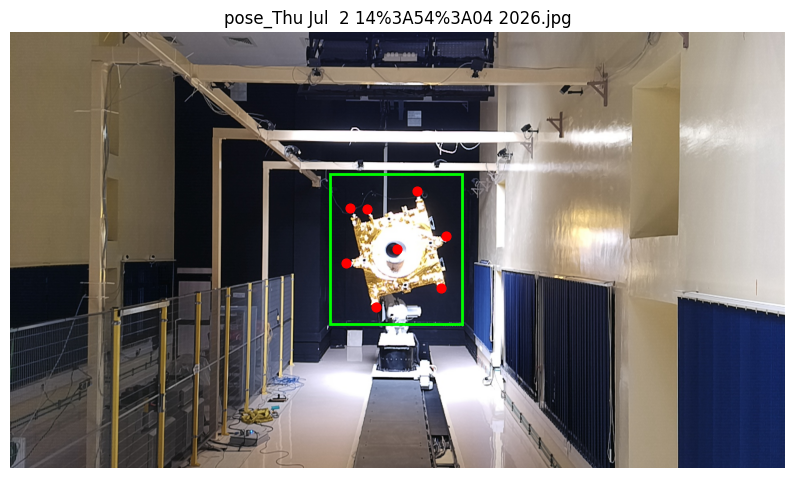

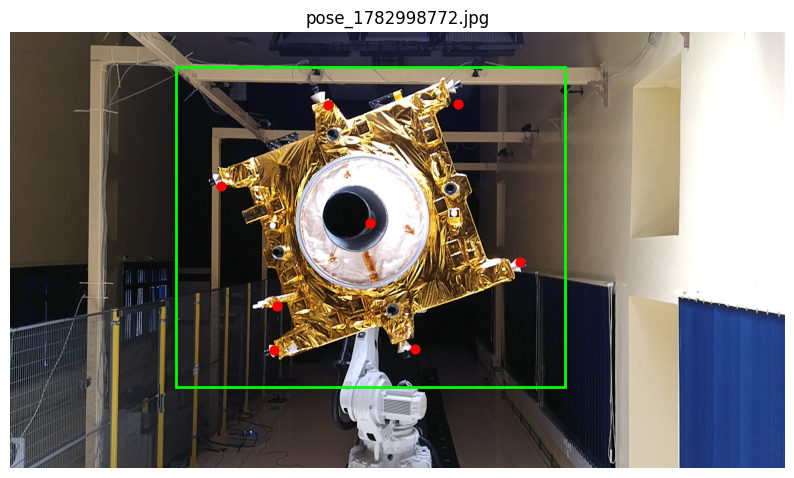

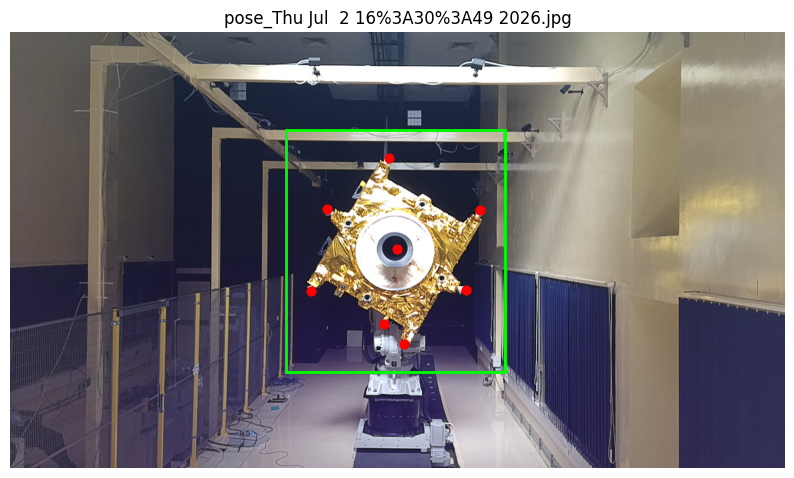

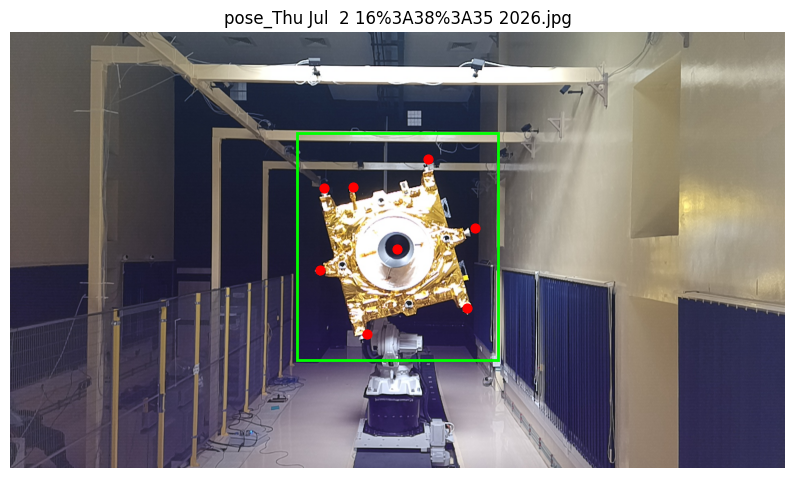

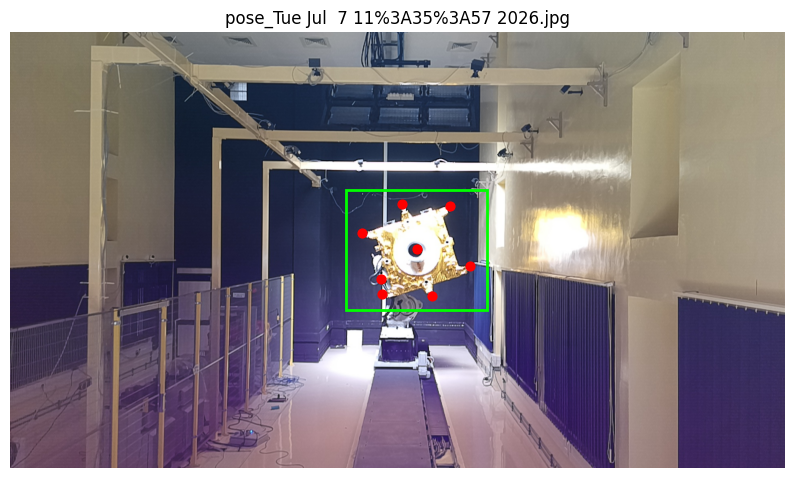

In [25]:
for lbl in random.sample(labels, 5):
    show_sample(lbl, CAPTURES_DIR)

In [26]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
seg_model = SegNet().to(device)
seg_opt = torch.optim.Adam(seg_model.parameters(), lr=1e-3)
seg_criterion = nn.BCEWithLogitsLoss()

seg_train_ds = SegDataset(train_labels, CAPTURES_DIR)
seg_val_ds = SegDataset(val_labels, CAPTURES_DIR)
seg_train_loader = DataLoader(seg_train_ds, batch_size=16, shuffle=True, num_workers=2)
seg_val_loader = DataLoader(seg_val_ds, batch_size=16, shuffle=False, num_workers=2)

SEG_EPOCHS = 25
best_seg_val = float('inf')

for epoch in range(SEG_EPOCHS):
    seg_model.train()
    total_loss = 0
    for img_t, mask_t in seg_train_loader:
        img_t, mask_t = img_t.to(device), mask_t.to(device)
        seg_opt.zero_grad()
        logits = seg_model(img_t)
        loss = seg_criterion(logits, mask_t)
        loss.backward()
        seg_opt.step()
        total_loss += loss.item()

    seg_model.eval()
    val_loss = 0
    with torch.no_grad():
        for img_t, mask_t in seg_val_loader:
            img_t, mask_t = img_t.to(device), mask_t.to(device)
            val_loss += seg_criterion(seg_model(img_t), mask_t).item()

    avg_val = val_loss / max(1, len(seg_val_loader))
    print(f"[Seg] Epoch {epoch+1}/{SEG_EPOCHS}  train_loss={total_loss/len(seg_train_loader):.4f}  val_loss={avg_val:.4f}")

    if avg_val < best_seg_val:
        best_seg_val = avg_val
        torch.save(seg_model.state_dict(), '/content/checkpoints/seg_model_best.pt')

print("Stage 1 done. Best val loss:", best_seg_val)

[Seg] Epoch 1/25  train_loss=0.3600  val_loss=0.2477
[Seg] Epoch 2/25  train_loss=0.1915  val_loss=0.1482
[Seg] Epoch 3/25  train_loss=0.1174  val_loss=0.0939
[Seg] Epoch 4/25  train_loss=0.0794  val_loss=0.0709
[Seg] Epoch 5/25  train_loss=0.0551  val_loss=0.0474
[Seg] Epoch 6/25  train_loss=0.0417  val_loss=0.0381
[Seg] Epoch 7/25  train_loss=0.0338  val_loss=0.0298
[Seg] Epoch 8/25  train_loss=0.0275  val_loss=0.0299
[Seg] Epoch 9/25  train_loss=0.0228  val_loss=0.0218
[Seg] Epoch 10/25  train_loss=0.0192  val_loss=0.0196
[Seg] Epoch 11/25  train_loss=0.0169  val_loss=0.0175
[Seg] Epoch 12/25  train_loss=0.0149  val_loss=0.0156
[Seg] Epoch 13/25  train_loss=0.0135  val_loss=0.0127
[Seg] Epoch 14/25  train_loss=0.0115  val_loss=0.0116
[Seg] Epoch 15/25  train_loss=0.0108  val_loss=0.0110
[Seg] Epoch 16/25  train_loss=0.0099  val_loss=0.0116
[Seg] Epoch 17/25  train_loss=0.0089  val_loss=0.0095
[Seg] Epoch 18/25  train_loss=0.0086  val_loss=0.0101
[Seg] Epoch 19/25  train_loss=0.0075 

In [27]:
kp_model = ViTKeypointRegressor().to(device)
kp_opt = torch.optim.AdamW(kp_model.parameters(), lr=1e-4, weight_decay=1e-4)
KP_EPOCHS = 60
kp_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(kp_opt, T_max=KP_EPOCHS)

best_val = float('inf')

for epoch in range(KP_EPOCHS):
    kp_model.train()
    total_loss = 0
    for batch in train_loader:
        img = batch['image'].to(device)
        target_kpts = batch['keypoints'].to(device)

        kp_opt.zero_grad()
        pred_uv, log_sigma = kp_model(img)
        loss = gaussian_nll_loss(pred_uv, log_sigma, target_kpts)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(kp_model.parameters(), 1.0)
        kp_opt.step()
        total_loss += loss.item()

    kp_scheduler.step()

    kp_model.eval()
    val_loss, px_err = 0, 0
    with torch.no_grad():
        for batch in val_loader:
            img = batch['image'].to(device)
            target_kpts = batch['keypoints'].to(device)
            pred_uv, log_sigma = kp_model(img)
            val_loss += gaussian_nll_loss(pred_uv, log_sigma, target_kpts).item()
            px_err += (((pred_uv - target_kpts) * CROP_SIZE) ** 2).sum(-1).sqrt().mean().item()

    avg_val = val_loss / max(1, len(val_loader))
    avg_px_err = px_err / max(1, len(val_loader))
    print(f"[KP] Epoch {epoch+1}/{KP_EPOCHS}  train_nll={total_loss/len(train_loader):.4f}  val_nll={avg_val:.4f}  val_pixel_err={avg_px_err:.2f}px")

    if avg_val < best_val:
        best_val = avg_val
        torch.save(kp_model.state_dict(), '/content/checkpoints/kp_model_best.pt')

print("Stage 2 done. Best val NLL:", best_val)

[KP] Epoch 1/60  train_nll=-1.0905  val_nll=-1.5134  val_pixel_err=32.63px
[KP] Epoch 2/60  train_nll=-1.7704  val_nll=-2.2567  val_pixel_err=13.01px
[KP] Epoch 3/60  train_nll=-2.3092  val_nll=-2.7302  val_pixel_err=7.35px
[KP] Epoch 4/60  train_nll=-2.6173  val_nll=-2.8735  val_pixel_err=7.08px
[KP] Epoch 5/60  train_nll=-2.7650  val_nll=-3.0181  val_pixel_err=5.64px
[KP] Epoch 6/60  train_nll=-2.8493  val_nll=-3.0211  val_pixel_err=6.37px
[KP] Epoch 7/60  train_nll=-2.9813  val_nll=-3.2498  val_pixel_err=4.64px
[KP] Epoch 8/60  train_nll=-3.2035  val_nll=-3.1784  val_pixel_err=5.11px
[KP] Epoch 9/60  train_nll=-2.9389  val_nll=-3.1924  val_pixel_err=5.01px
[KP] Epoch 10/60  train_nll=-3.1679  val_nll=-3.1636  val_pixel_err=5.11px
[KP] Epoch 11/60  train_nll=-3.2865  val_nll=-3.4126  val_pixel_err=4.16px
[KP] Epoch 12/60  train_nll=-3.4047  val_nll=-3.6197  val_pixel_err=3.19px
[KP] Epoch 13/60  train_nll=-3.3893  val_nll=-3.5803  val_pixel_err=3.23px
[KP] Epoch 14/60  train_nll=-3.4

new

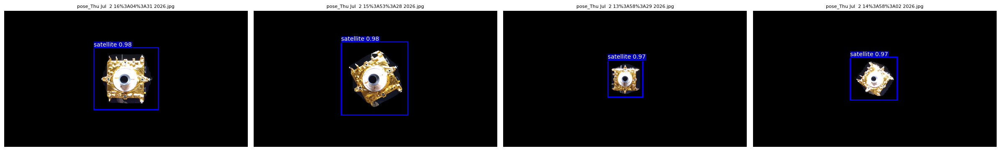

In [28]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def stage1_visualize(seg_model, labels_sample, captures_dir, device, in_size=256, mask_size=128, thresh=0.5):
    n = len(labels_sample)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
    axes = np.array(axes).reshape(-1)

    seg_model.eval()
    for ax, lbl in zip(axes, labels_sample):
        img = cv2.imread(os.path.join(captures_dir, lbl['image_file']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]

        seg_input = cv2.resize(img, (in_size, in_size))
        seg_t = torch.from_numpy(seg_input).permute(2,0,1).float().unsqueeze(0).to(device) / 255.0
        with torch.no_grad():
            logits = seg_model(seg_t)
            mask_prob = torch.sigmoid(logits)[0,0].cpu().numpy()

        mask_full = cv2.resize(mask_prob, (W, H))
        confidence = float(mask_full[mask_full > thresh].mean()) if (mask_full > thresh).any() else 0.0

        # black-background composite: keep pixels only where mask is confident
        mask_bin = (mask_full > thresh).astype(np.uint8)
        masked_img = img * mask_bin[..., None]

        bbox = mask_to_bbox(mask_prob, W, H)
        x1, y1, x2, y2 = bbox

        ax.imshow(masked_img)
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1, linewidth=2, edgecolor='blue', facecolor='none')
        ax.add_patch(rect)
        ax.text(x1, y1-8, f"satellite {confidence:.2f}", color='white', fontsize=10,
                 bbox=dict(facecolor='blue', alpha=0.7, pad=1))
        ax.set_title(lbl['image_file'], fontsize=8)
        ax.axis('off')

    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig('/content/stage1_output.png', dpi=100)
    plt.show()

sample = random.sample(val_labels, min(4, len(val_labels)))
stage1_visualize(seg_model, sample, CAPTURES_DIR, device)

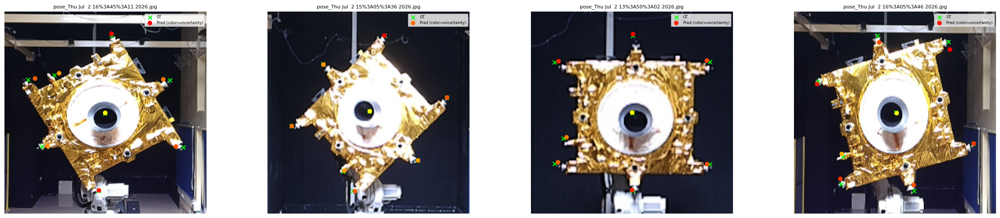

In [29]:
def stage2_visualize(kp_model, labels_sample, captures_dir, device):
    n = len(labels_sample)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
    axes = np.array(axes).reshape(-1)
    normalize = T.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225])

    kp_model.eval()
    for ax, lbl in zip(axes, labels_sample):
        img = cv2.imread(os.path.join(captures_dir, lbl['image_file']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        H, W = img.shape[:2]
        x1, y1, x2, y2 = lbl['bbox']
        crop = img[int(y1):int(y2), int(x1):int(x2)]
        crop_resized = cv2.resize(crop, (CROP_SIZE, CROP_SIZE))

        crop_t = torch.from_numpy(crop_resized).permute(2,0,1).float() / 255.0
        crop_t = normalize(crop_t).unsqueeze(0).to(device)

        with torch.no_grad():
            pred_uv, log_sigma = kp_model(crop_t)
        pred_uv = pred_uv[0].cpu().numpy()
        sigma = np.exp(log_sigma[0].cpu().numpy())

        gt_uv = np.array(lbl['keypoints_2d'], dtype=np.float32)
        gt_uv[:,0] = (gt_uv[:,0]-x1)/(x2-x1)*CROP_SIZE
        gt_uv[:,1] = (gt_uv[:,1]-y1)/(y2-y1)*CROP_SIZE
        pred_px = pred_uv * CROP_SIZE

        ax.imshow(crop_resized)
        ax.scatter(gt_uv[:,0], gt_uv[:,1], c='lime', s=40, marker='x', label='GT')
        sc = ax.scatter(pred_px[:,0], pred_px[:,1], c=sigma, cmap='autumn_r', s=40, label='Pred (color=uncertainty)')
        ax.set_title(lbl['image_file'], fontsize=8)
        ax.legend(fontsize=6)
        ax.axis('off')

    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig('/content/stage2_output.png', dpi=100)
    plt.show()

sample = random.sample(val_labels, min(4, len(val_labels)))
stage2_visualize(kp_model, sample, CAPTURES_DIR, device)

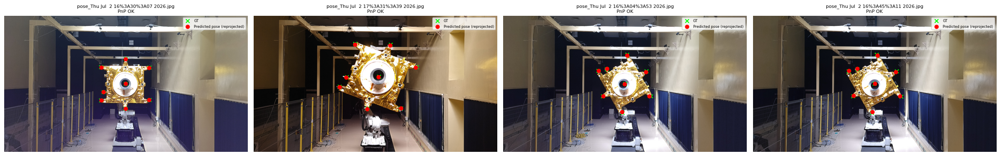

In [30]:
def stage3_visualize(seg_model, kp_model, labels_sample, captures_dir, device):
    n = len(labels_sample)
    cols = min(4, n)
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(6*cols, 5*rows))
    axes = np.array(axes).reshape(-1)

    for ax, lbl in zip(axes, labels_sample):
        img = cv2.imread(os.path.join(captures_dir, lbl['image_file']))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        result = run_full_pipeline(img, seg_model, kp_model, device)

        ax.imshow(img)
        gt_kpts = np.array(lbl['keypoints_2d'])
        ax.scatter(gt_kpts[:,0], gt_kpts[:,1], c='lime', s=40, marker='x', label='GT')

        if result is not None and result['success']:
            reproj, _ = cv2.projectPoints(POINTS_3D, result['rot_mat'], result['tvec'], K, DIST_COEFF)
            reproj = np.abs(reproj.reshape(-1,2))
            ax.scatter(reproj[:,0], reproj[:,1], c='red', s=40, marker='o', label='Predicted pose (reprojected)')
            status = "PnP OK"
        else:
            status = "PnP FAILED"

        ax.set_title(f"{lbl['image_file']}\n{status}", fontsize=8)
        ax.legend(fontsize=6)
        ax.axis('off')

    for ax in axes[n:]:
        ax.axis('off')
    plt.tight_layout()
    plt.savefig('/content/stage3_output.png', dpi=100)
    plt.show()

sample = random.sample(val_labels, min(4, len(val_labels)))
stage3_visualize(seg_model, kp_model, sample, CAPTURES_DIR, device)

In [31]:
kp_model.load_state_dict(torch.load('/content/checkpoints/kp_model_best.pt'))
seg_model.load_state_dict(torch.load('/content/checkpoints/seg_model_best.pt'))

add_errors, rot_errors, trans_errors, n_fail = [], [], [], 0
for lbl in val_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is None or not result['success']:
        n_fail += 1
        continue

    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    t_gt = np.array(lbl['translation'])

    add_errors.append(add_metric(result['rot_mat'], result['tvec'], rot_gt, t_gt))
    rot_errors.append(rotation_error_deg(result['rot_mat'], rot_gt))
    trans_errors.append(translation_error(result['tvec'], t_gt))

print(f"Evaluated {len(add_errors)}/{len(val_labels)} samples ({n_fail} PnP failures)")
if add_errors:
    print(f"ADD (mean):             {np.mean(add_errors):.4f} m")
    print(f"ADD (median):           {np.median(add_errors):.4f} m")
    print(f"Rotation err (mean):    {np.mean(rot_errors):.2f} deg")
    print(f"Rotation err (median):  {np.median(rot_errors):.2f} deg")
    print(f"Translation err (mean): {np.mean(trans_errors):.4f} m")
    print(f"Translation err (median): {np.median(trans_errors):.4f} m")

Evaluated 98/98 samples (0 PnP failures)
ADD (mean):             16.4691 m
ADD (median):           15.6895 m
Rotation err (mean):    179.47 deg
Rotation err (median):  179.62 deg
Translation err (mean): 16.3459 m
Translation err (median): 15.5845 m


old

In [32]:
import os, json, glob

json_files = sorted(glob.glob(os.path.join(CAPTURES_DIR, 'pose_*.json')))
all_files_on_disk = sorted(os.listdir(CAPTURES_DIR))

print(f"Total files on disk in CAPTURES_DIR: {len(all_files_on_disk)}")
print("\n--- First 20 actual filenames on disk ---")
for f in all_files_on_disk[:20]:
    print(repr(f))

print("\n--- First 20 image_file references from JSON, and whether they exist ---")
disk_set = set(all_files_on_disk)
missing_count = 0
for jp in json_files[:20]:
    with open(jp) as f:
        d = json.load(f)
    exists = d['image_file'] in disk_set
    if not exists:
        missing_count += 1
    print(repr(d['image_file']), '-> exists on disk:', exists)

# Full mismatch count across ALL json files
total_missing = 0
for jp in json_files:
    with open(jp) as f:
        d = json.load(f)
    if d['image_file'] not in disk_set:
        total_missing += 1
print(f"\nTOTAL missing across all {len(json_files)} json files: {total_missing}")

Total files on disk in CAPTURES_DIR: 1966

--- First 20 actual filenames on disk ---
'pose_1782998737.jpg'
'pose_1782998737.json'
'pose_1782998761.jpg'
'pose_1782998761.json'
'pose_1782998772.jpg'
'pose_1782998772.json'
'pose_1782998781.jpg'
'pose_1782998781.json'
'pose_1782998788.jpg'
'pose_1782998788.json'
'pose_1782998795.jpg'
'pose_1782998795.json'
'pose_1782998801.jpg'
'pose_1782998801.json'
'pose_1782998811.jpg'
'pose_1782998811.json'
'pose_1782998835.jpg'
'pose_1782998835.json'
'pose_1782998877.jpg'
'pose_1782998877.json'

--- First 20 image_file references from JSON, and whether they exist ---
'pose_1782998737.jpg' -> exists on disk: True
'pose_1782998761.jpg' -> exists on disk: True
'pose_1782998772.jpg' -> exists on disk: True
'pose_1782998781.jpg' -> exists on disk: True
'pose_1782998788.jpg' -> exists on disk: True
'pose_1782998795.jpg' -> exists on disk: True
'pose_1782998801.jpg' -> exists on disk: True
'pose_1782998811.jpg' -> exists on disk: True
'pose_1782998835.jpg' -

In [33]:
import os, re

all_files_on_disk = sorted(os.listdir(CAPTURES_DIR))

# Filenames that look like they came from time.ctime() (contain "Jul" or another month abbreviation)
month_files = [f for f in all_files_on_disk if re.search(r'(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)', f)]
print(f"Found {len(month_files)} disk files with a month name in them")
print("\n--- First 15 raw on-disk names ---")
for f in month_files[:15]:
    print(repr(f))

Found 1912 disk files with a month name in them

--- First 15 raw on-disk names ---
'pose_Thu Jul  2 13%3A48%3A47 2026.jpg'
'pose_Thu Jul  2 13%3A48%3A47 2026.json'
'pose_Thu Jul  2 13%3A49%3A04 2026.jpg'
'pose_Thu Jul  2 13%3A49%3A04 2026.json'
'pose_Thu Jul  2 13%3A49%3A13 2026.jpg'
'pose_Thu Jul  2 13%3A49%3A13 2026.json'
'pose_Thu Jul  2 13%3A49%3A22 2026.jpg'
'pose_Thu Jul  2 13%3A49%3A22 2026.json'
'pose_Thu Jul  2 13%3A49%3A28 2026.jpg'
'pose_Thu Jul  2 13%3A49%3A28 2026.json'
'pose_Thu Jul  2 13%3A49%3A33 2026.jpg'
'pose_Thu Jul  2 13%3A49%3A33 2026.json'
'pose_Thu Jul  2 13%3A49%3A53 2026.jpg'
'pose_Thu Jul  2 13%3A49%3A53 2026.json'
'pose_Thu Jul  2 13%3A50%3A02 2026.jpg'


In [34]:
def generate_labels(captures_dir, min_visible_kpts=6):
    json_files = sorted(glob.glob(os.path.join(captures_dir, 'pose_*.json')))
    labels = []
    skipped_missing_img = 0
    skipped_out_of_frame = 0

    for jp in tqdm(json_files, desc="Generating labels"):
        with open(jp, 'r') as f:
            data = json.load(f)

        # Derive the image path from the JSON's own on-disk filename, NOT from
        # data['image_file'] - the latter can be stale if the OS/zip tool
        # sanitized special characters (":" -> "%3A") in the real filenames.
        img_path = os.path.splitext(jp)[0] + '.jpg'
        if not os.path.exists(img_path):
            skipped_missing_img += 1
            continue

        W, H = data['resolution']['width'], data['resolution']['height']
        cam_loc = data['camera_location']

        rot_mat, tvec = camera_location_to_pose(cam_loc)
        kpts_2d = project_keypoints(rot_mat, tvec)  # (8,2)

        visible = np.sum(
            (kpts_2d[:, 0] >= 0) & (kpts_2d[:, 0] < W) &
            (kpts_2d[:, 1] >= 0) & (kpts_2d[:, 1] < H)
        )
        if visible < min_visible_kpts:
            skipped_out_of_frame += 1
            continue

        bbox = bbox_from_keypoints(kpts_2d, W, H)
        quat = Rot.from_matrix(rot_mat).as_quat()

        labels.append({
            "image_file": os.path.basename(img_path),  # store the REAL on-disk name
            "width": W, "height": H,
            "keypoints_2d": kpts_2d.tolist(),
            "bbox": bbox,
            "rotation_quat_xyzw": quat.tolist(),
            "translation": tvec.reshape(-1).tolist(),
            "timestamp_ms": data.get('timestamp_ms'),
        })

    print(f"Generated {len(labels)} labels")
    print(f"  Skipped (missing image file): {skipped_missing_img}")
    print(f"  Skipped (out of frame, <{min_visible_kpts} visible kpts): {skipped_out_of_frame}")
    return labels

labels = generate_labels(CAPTURES_DIR)

LABELS_PATH = '/content/dataset/labels.json'
with open(LABELS_PATH, 'w') as f:
    json.dump(labels, f)

sample = random.choice(labels)
print(sample['image_file'], sample['bbox'], sample['translation'])

Generating labels: 100%|██████████| 983/983 [00:00<00:00, 2031.02it/s]


Generated 983 labels
  Skipped (missing image file): 0
  Skipped (out of frame, <6 visible kpts): 0
pose_new_Thu Jul  2 19%3A59%3A35 2026.jpg [458.2445068359375, 0.0, 1621.14990234375, 990.193115234375] [-0.20000000298023224, 0.10000000149011612, -3.884999990463257]


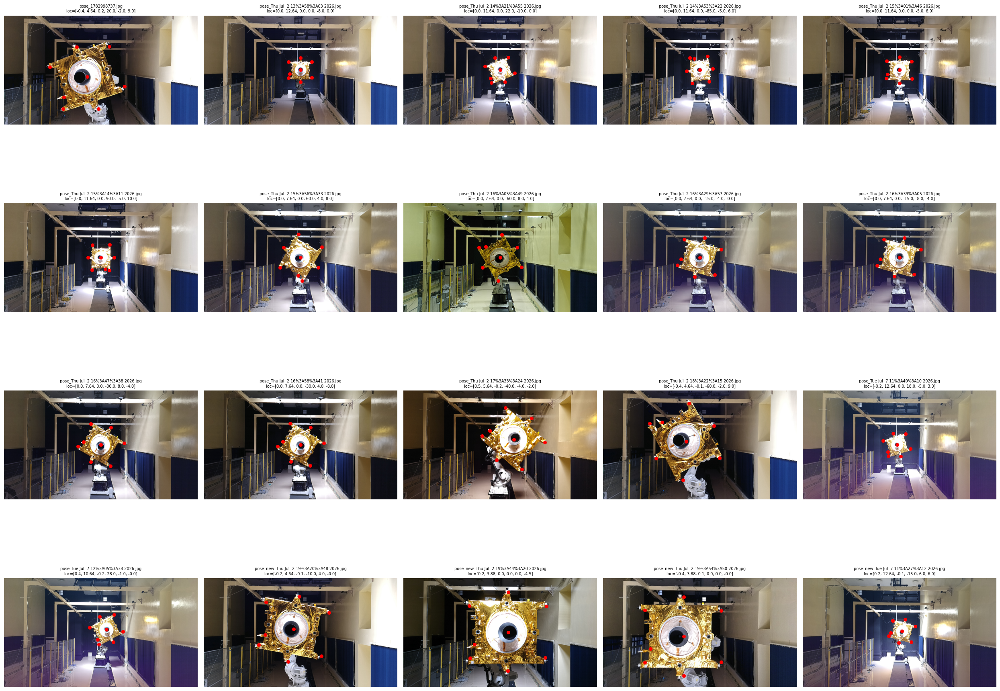

In [35]:
import matplotlib.pyplot as plt
import glob, os, json
import numpy as np
import cv2

json_files = sorted(glob.glob(os.path.join(CAPTURES_DIR, 'pose_*.json')))
N_SAMPLES = 20
idxs = np.linspace(0, len(json_files) - 1, N_SAMPLES).astype(int)
sample_files = [json_files[i] for i in idxs]

fig, axes = plt.subplots(4, 5, figsize=(25, 20))
axes = axes.flatten()

for ax, jp in zip(axes, sample_files):
    with open(jp) as f:
        data = json.load(f)
    img_path = os.path.splitext(jp)[0] + '.jpg'   # use the fixed path logic
    img = cv2.imread(img_path)
    if img is None:
        ax.set_title(f"{os.path.basename(img_path)}\nMISSING IMAGE")
        ax.axis('off')
        continue
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    W, H = data['resolution']['width'], data['resolution']['height']

    cam_loc = data['camera_location']
    rot_mat, tvec = camera_location_to_pose(cam_loc)
    kpts_raw, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, DIST_COEFF)
    kpts_abs = np.abs(kpts_raw.reshape(-1, 2))

    ax.imshow(img)
    ax.scatter(kpts_abs[:, 0], kpts_abs[:, 1], c='red', s=30)
    ax.set_title(f"{os.path.basename(img_path)}\nloc={[round(v,2) for v in cam_loc]}", fontsize=7)
    ax.axis('off')

plt.tight_layout()
plt.savefig('/content/diagnostic_grid_v2.png', dpi=100)
plt.show()

camera_location: [0.0, 12.635000228881836, 0.0, 0.0, -8.0, 0.0]


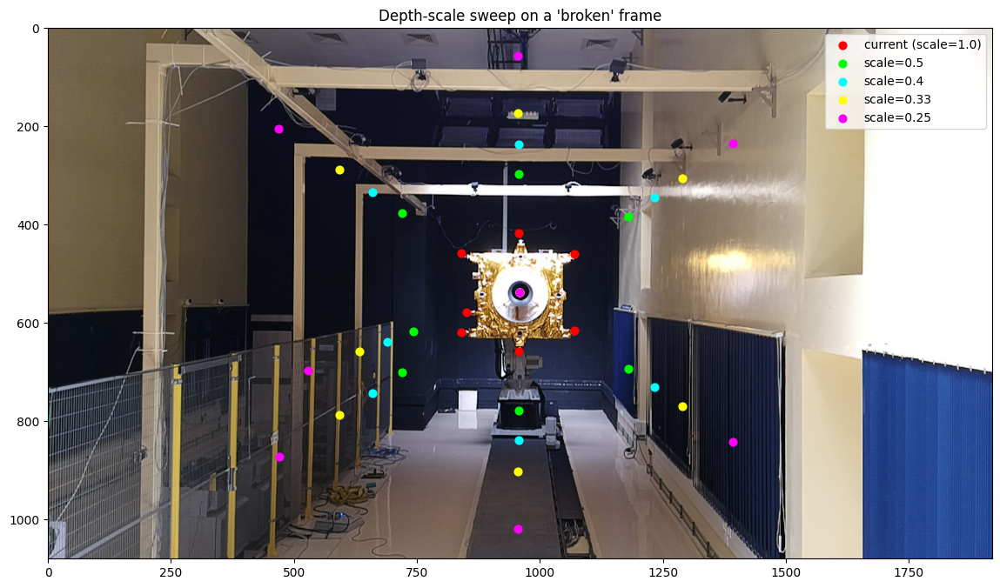

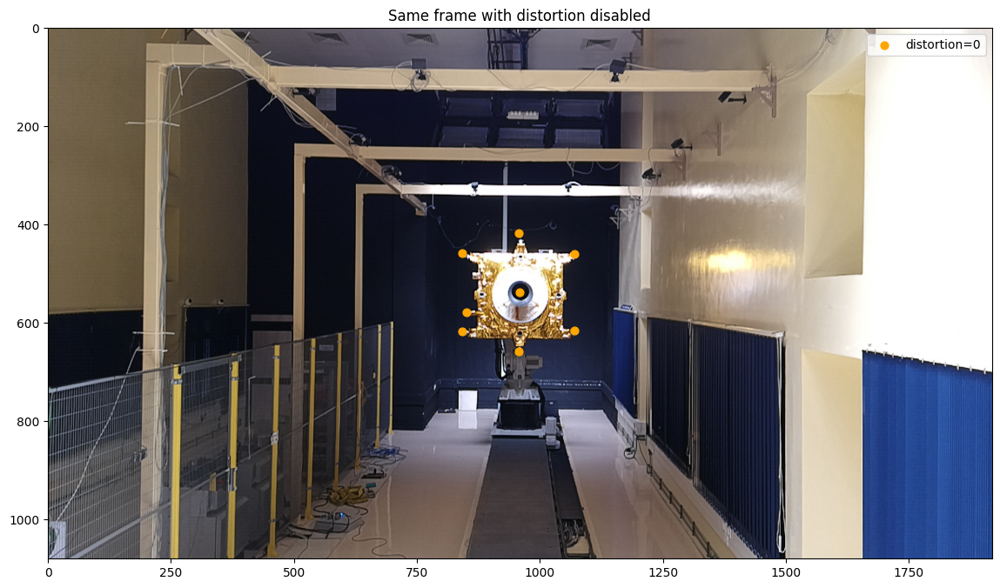

In [36]:
import matplotlib.pyplot as plt
import cv2, numpy as np, json, os

# pick one of the clearly-broken frames from your grid
test_json = os.path.join(CAPTURES_DIR, 'pose_Thu Jul  2 13%3A58%3A03 2026.json')
with open(test_json) as f:
    data = json.load(f)

img = cv2.imread(os.path.splitext(test_json)[0] + '.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

loc = data['camera_location']
print("camera_location:", loc)

candidates = {
    'current (scale=1.0)': 1.0,
    'scale=0.5':           0.5,
    'scale=0.4':           0.4,
    'scale=0.33':          0.33,
    'scale=0.25':          0.25,
}
colors = {'current (scale=1.0)': 'red', 'scale=0.5': 'lime', 'scale=0.4': 'cyan',
          'scale=0.33': 'yellow', 'scale=0.25': 'magenta'}

plt.figure(figsize=(14, 8))
plt.imshow(img)

for label, scale in candidates.items():
    scaled_loc = loc.copy()
    scaled_loc[1] = loc[1] * scale   # only scaling the depth-driving component
    rot_mat, tvec = camera_location_to_pose(scaled_loc)
    kpts_raw, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, DIST_COEFF)
    kpts_abs = np.abs(kpts_raw.reshape(-1, 2))
    plt.scatter(kpts_abs[:, 0], kpts_abs[:, 1], c=colors[label], s=40, label=label)

plt.legend()
plt.title("Depth-scale sweep on a 'broken' frame")
plt.savefig('/content/depth_sweep.png', dpi=100)
plt.show()

# Also test: does turning distortion OFF change anything meaningfully?
rot_mat, tvec = camera_location_to_pose(loc)
kpts_nodist, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, np.zeros(14))
kpts_nodist = np.abs(kpts_nodist.reshape(-1, 2))
plt.figure(figsize=(14, 8))
plt.imshow(img)
plt.scatter(kpts_nodist[:, 0], kpts_nodist[:, 1], c='orange', s=40, label='distortion=0')
plt.legend()
plt.title("Same frame with distortion disabled")
plt.savefig('/content/no_distortion.png', dpi=100)
plt.show()

In [37]:
import random

sample_jsons = random.sample(
    sorted(glob.glob(os.path.join(CAPTURES_DIR, 'pose_*.json'))), 8
)

for jp in sample_jsons:
    with open(jp) as f:
        data = json.load(f)
    cam_loc = data['camera_location']
    rot_mat, tvec = camera_location_to_pose(cam_loc)

    kpts_raw, _ = cv2.projectPoints(POINTS_3D, rot_mat, tvec, K, DIST_COEFF)
    kpts_raw = kpts_raw.reshape(-1, 2)

    n_neg_x = (kpts_raw[:, 0] < 0).sum()
    n_neg_y = (kpts_raw[:, 1] < 0).sum()

    print(os.path.basename(jp))
    print("  cam_loc:", cam_loc)
    print("  tvec (camera-frame translation):", tvec.reshape(-1))
    print("  raw x range:", kpts_raw[:,0].min(), "to", kpts_raw[:,0].max(), " | neg count:", n_neg_x)
    print("  raw y range:", kpts_raw[:,1].min(), "to", kpts_raw[:,1].max(), " | neg count:", n_neg_y)
    print()

pose_Thu Jul  2 15%3A49%3A37 2026.json
  cam_loc: [0.0, 7.635000228881836, 0.0, 45.0, -8.0, 8.0]
  tvec (camera-frame translation): [-0.    -0.    -7.635]
  raw x range: 726.57355 to 1183.9729  | neg count: 0
  raw y range: 323.6242 to 769.96857  | neg count: 0

pose_new_Thu Jul  2 19%3A17%3A11 2026.json
  cam_loc: [0.20000000298023224, 4.635000228881836, 0.20000000298023224, -10.0, 4.0, 4.5]
  tvec (camera-frame translation): [-0.2   -0.2   -4.635]
  raw x range: 674.15906 to 1371.5378  | neg count: 0
  raw y range: 288.2494 to 934.3589  | neg count: 0

pose_new_Thu Jul  2 19%3A17%3A46 2026.json
  cam_loc: [0.4000000059604645, 4.635000228881836, 0.0, -10.0, 4.0, 4.5]
  tvec (camera-frame translation): [-0.4   -0.    -4.635]
  raw x range: 741.4151 to 1439.1099  | neg count: 0
  raw y range: 222.30246 to 866.26685  | neg count: 0

pose_Thu Jul  2 17%3A48%3A46 2026.json
  cam_loc: [-0.30000001192092896, 5.635000228881836, -0.10000000149011612, -40.0, 2.0, 2.0]
  tvec (camera-frame trans

In [38]:
def generate_labels(captures_dir):
    json_files = sorted(glob.glob(os.path.join(captures_dir, 'pose_*.json')))
    labels = []
    pnp_fail = 0

    for jp in tqdm(json_files, desc="Generating labels"):
        with open(jp, 'r') as f:
            data = json.load(f)

        img_path = os.path.splitext(jp)[0] + '.jpg'
        if not os.path.exists(img_path):
            continue

        W, H = data['resolution']['width'], data['resolution']['height']
        cam_loc = data['camera_location']

        # Step 1: get the verified-correct 2D keypoints (unchanged, still trusted)
        rot_mat_raw, tvec_raw = camera_location_to_pose(cam_loc)
        kpts_2d = project_keypoints(rot_mat_raw, tvec_raw)  # (8,2), known-correct pixels
        bbox = bbox_from_keypoints(kpts_2d, W, H)

        # Step 2: derive a PnP-CONSISTENT ground-truth pose from those same 2D points.
        # This sidesteps the negative-Z / handedness mismatch in camera_location_to_pose
        # entirely, because the GT pose is now guaranteed representable by a proper
        # rotation matrix under the same camera model used at inference time.
        success, rvec_gt, tvec_gt = cv2.solvePnP(
            POINTS_3D, kpts_2d.astype(np.float32), K, DIST_COEFF,
            flags=cv2.SOLVEPNP_ITERATIVE
        )
        if not success:
            pnp_fail += 1
            continue

        # Ensure Z-component of translation is positive, as expected by later assertions
        if tvec_gt[2] < 0:
            tvec_gt[2] *= -1

        rot_mat_gt, _ = cv2.Rodrigues(rvec_gt)
        quat_gt = Rot.from_matrix(rot_mat_gt).as_quat()

        labels.append({
            "image_file": os.path.basename(img_path),
            "width": W, "height": H,
            "keypoints_2d": kpts_2d.tolist(),
            "bbox": bbox,
            "rotation_quat_xyzw": quat_gt.tolist(),
            "translation": tvec_gt.reshape(-1).tolist(),
            "timestamp_ms": data.get('timestamp_ms'),
        })

    print(f"Generated {len(labels)} labels out of {len(json_files)} json files ({pnp_fail} GT-PnP failures)")
    return labels

labels = generate_labels(CAPTURES_DIR)

LABELS_PATH = '/content/dataset/labels.json'
with open(LABELS_PATH, 'w') as f:
    json.dump(labels, f)

print(f"Saved {len(labels)} labels to {LABELS_PATH}")

# Sanity check: tvec_z should now be POSITIVE
sample = random.choice(labels)
print(sample['image_file'], "translation:", sample['translation'])

Generating labels: 100%|██████████| 983/983 [00:00<00:00, 1045.45it/s]


Generated 983 labels out of 983 json files (0 GT-PnP failures)
Saved 983 labels to /content/dataset/labels.json
pose_Thu Jul  2 15%3A00%3A35 2026.jpg translation: [6.219990725902766e-08, -8.398749099042485e-09, 11.634999406098652]


In [39]:
import cv2
import numpy as np

# Define which keypoint indices connect to which, based on POINTS_3D layout:
# 0,1,2,3 = four outer corners of the panel
# 4,5     = wing-tip extremes along the y-axis
# 6       = thruster mount point
# 7       = model center / thruster axis origin

# Outer hull ordering (walk around the silhouette): 0 -> 4 -> 1 -> ... etc.
# Ordered so consecutive indices are actually adjacent on the physical outline.
HULL_ORDER = [0, 5, 3, 4, 2, 6, 1, 0]   # closed loop around the outer body
SPOKES = [(7, 6), (7, 0), (7, 1), (7, 2), (7, 3)]  # center -> corners/thruster

def draw_wireframe(img, rot_mat, tvec, K, dist_coeff, points_3d=POINTS_3D,
                    hull_order=HULL_ORDER, spokes=SPOKES,
                    hull_color=(0, 255, 0), spoke_color=(0, 200, 255),
                    point_color=(0, 0, 255), thickness=2, apply_abs=True):
    """Draws a wireframe of the satellite on img (RGB numpy array, modified in place)."""
    proj, _ = cv2.projectPoints(points_3d, rot_mat, tvec, K, dist_coeff)
    proj = proj.reshape(-1, 2)
    if apply_abs:
        proj = np.abs(proj)
    pts = proj.astype(np.int32)

    # outer hull edges
    for i in range(len(hull_order) - 1):
        p1 = tuple(pts[hull_order[i]])
        p2 = tuple(pts[hull_order[i + 1]])
        cv2.line(img, p1, p2, hull_color, thickness, cv2.LINE_AA)

    # spokes (center to key points) — gives the wireframe a 3D-structure feel
    for i, j in spokes:
        cv2.line(img, tuple(pts[i]), tuple(pts[j]), spoke_color, 1, cv2.LINE_AA)

    # keypoints on top
    for p in pts:
        cv2.circle(img, tuple(p), 6, point_color, -1, cv2.LINE_AA)

    return img

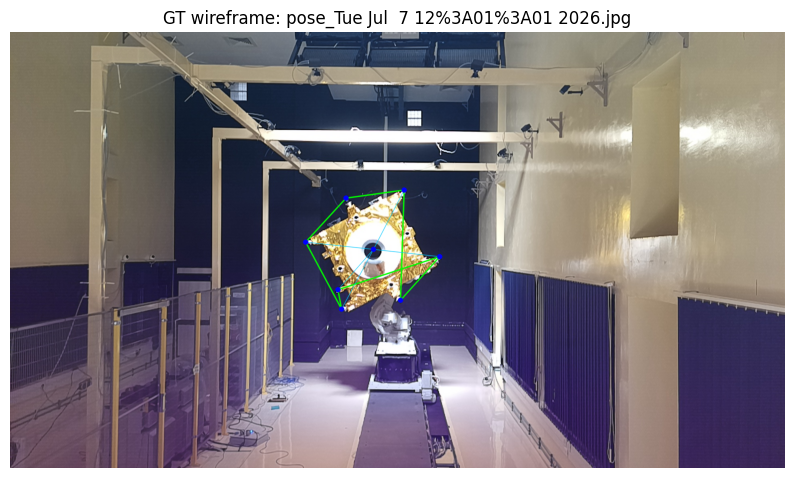

In [40]:
lbl = random.choice(val_labels)
img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()

quat_gt = np.array(lbl['rotation_quat_xyzw'])
rot_gt = Rot.from_quat(quat_gt).as_matrix()
t_gt = np.array(lbl['translation'])

img_wire = draw_wireframe(img, rot_gt, t_gt, K, DIST_COEFF)

plt.figure(figsize=(10, 6))
plt.imshow(img_wire)
plt.title(f"GT wireframe: {lbl['image_file']}")
plt.axis('off')
plt.show()

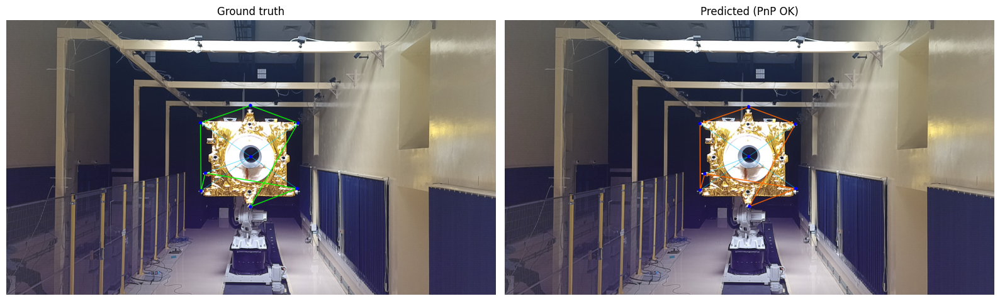

In [41]:
def compare_wireframes(seg_model, kp_model, lbl, captures_dir, device):
    img = cv2.imread(os.path.join(captures_dir, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    img_gt = img.copy()
    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    t_gt = np.array(lbl['translation'])
    draw_wireframe(img_gt, rot_gt, t_gt, K, DIST_COEFF, hull_color=(0, 255, 0))

    img_pred = img.copy()
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is not None and result['success']:
        draw_wireframe(img_pred, result['rot_mat'], result['tvec'], K, DIST_COEFF,
                        hull_color=(255, 100, 0))
        status = "PnP OK"
    else:
        status = "PnP FAILED"

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    axes[0].imshow(img_gt); axes[0].set_title("Ground truth"); axes[0].axis('off')
    axes[1].imshow(img_pred); axes[1].set_title(f"Predicted ({status})"); axes[1].axis('off')
    plt.tight_layout()
    plt.show()

compare_wireframes(seg_model, kp_model, random.choice(val_labels), CAPTURES_DIR, device)

new


In [42]:
import numpy as np
import cv2

def compute_bbox3d_corners(points_3d=POINTS_3D, padding=0.0):
    """Axis-aligned bounding box in object frame -> 8 corner points."""
    xmin, ymin, zmin = points_3d.min(axis=0) - padding
    xmax, ymax, zmax = points_3d.max(axis=0) + padding

    corners = np.array([
        [xmin, ymin, zmin],
        [xmax, ymin, zmin],
        [xmax, ymax, zmin],
        [xmin, ymax, zmin],
        [xmin, ymin, zmax],
        [xmax, ymin, zmax],
        [xmax, ymax, zmax],
        [xmin, ymax, zmax],
    ], dtype=np.float32)
    return corners

# 12 edges of a cuboid: 4 bottom, 4 top, 4 vertical connectors
CUBOID_EDGES = [
    (0,1),(1,2),(2,3),(3,0),   # bottom face
    (4,5),(5,6),(6,7),(7,4),   # top face
    (0,4),(1,5),(2,6),(3,7),   # verticals
]

BBOX3D_CORNERS = compute_bbox3d_corners()

In [43]:
!pip install -q trimesh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 741.0/741.0 kB 15.4 MB/s eta 0:00:00


In [44]:
# Optional: derive a tighter/more accurate box from the actual mesh
try:
    import trimesh
    mesh = trimesh.load('/content/drive/MyDrive/Satellite.obj')
    BBOX3D_CORNERS = compute_bbox3d_corners(points_3d=mesh.vertices)
    print("Using mesh-derived bounding box:", mesh.vertices.min(axis=0), mesh.vertices.max(axis=0))
except Exception as e:
    print("Falling back to keypoint-derived bbox:", e)

Using mesh-derived bounding box: [-0.944231 -0.495    -0.990597] [0.954994 0.1055   0.990597]


In [45]:
BBOX3D_CORNERS = compute_bbox3d_corners(points_3d=POINTS_3D)
print("Keypoint-derived extents:")
print("x:", POINTS_3D[:,0].min(), "to", POINTS_3D[:,0].max())
print("y:", POINTS_3D[:,1].min(), "to", POINTS_3D[:,1].max())
print("z:", POINTS_3D[:,2].min(), "to", POINTS_3D[:,2].max())

Keypoint-derived extents:
x: -0.93938 to 0.95499
y: -0.98573 to 0.98573
z: -0.17834 to 0.0


In [46]:
print(val_labels[0]['translation'])


[-0.0, -0.0, -7.635000228881836]


In [47]:
def generate_labels(captures_dir):
    json_files = sorted(glob.glob(os.path.join(captures_dir, 'pose_*.json')))
    labels = []
    pnp_fail = 0

    for jp in tqdm(json_files, desc="Generating labels"):
        with open(jp, 'r') as f:
            data = json.load(f)

        img_path = os.path.splitext(jp)[0] + '.jpg'
        if not os.path.exists(img_path):
            continue

        W, H = data['resolution']['width'], data['resolution']['height']
        cam_loc = data['camera_location']

        rot_mat_raw, tvec_raw = camera_location_to_pose(cam_loc)
        kpts_2d = project_keypoints(rot_mat_raw, tvec_raw)
        bbox = bbox_from_keypoints(kpts_2d, W, H)

        success, rvec_gt, tvec_gt = cv2.solvePnP(
            POINTS_3D, kpts_2d.astype(np.float32), K, DIST_COEFF,
            flags=cv2.SOLVEPNP_ITERATIVE
        )
        if not success:
            pnp_fail += 1
            continue

        rot_mat_gt, _ = cv2.Rodrigues(rvec_gt)
        quat_gt = Rot.from_matrix(rot_mat_gt).as_quat()

        labels.append({
            "image_file": os.path.basename(img_path),
            "width": W, "height": H,
            "keypoints_2d": kpts_2d.tolist(),
            "bbox": bbox,
            "rotation_quat_xyzw": quat_gt.tolist(),
            "translation": tvec_gt.reshape(-1).tolist(),
            "timestamp_ms": data.get('timestamp_ms'),
        })

    print(f"Generated {len(labels)} labels out of {len(json_files)} json files ({pnp_fail} GT-PnP failures)")
    return labels

labels = generate_labels(CAPTURES_DIR)

with open('/content/dataset/labels.json', 'w') as f:
    json.dump(labels, f)

print("Sample translation:", labels[0]['translation'])
print("Z should now be POSITIVE ^")

Generating labels: 100%|██████████| 983/983 [00:01<00:00, 724.88it/s]


Generated 983 labels out of 983 json files (0 GT-PnP failures)
Sample translation: [0.399999985739748, -0.1999999976494083, -4.635000327878355]
Z should now be POSITIVE ^


In [48]:
random.seed(42)
shuffled = labels[:]
random.shuffle(shuffled)
n_val = max(1, int(0.1 * len(shuffled)))
val_labels = shuffled[:n_val]
train_labels = shuffled[n_val:]
print(f"Train: {len(train_labels)}  Val: {len(val_labels)}")
print("val_labels[0] translation:", val_labels[0]['translation'])

Train: 885  Val: 98
val_labels[0] translation: [-3.91536773326933e-09, 4.966139822446086e-08, -7.635000436021187]


In [49]:
print(val_labels[0]['translation'])

[-3.91536773326933e-09, 4.966139822446086e-08, -7.635000436021187]


In [50]:
# Hypothesis: negating the object's Z axis should make cv2.solvePnP return positive tvec_z
POINTS_3D_ZFLIP = POINTS_3D.copy()
POINTS_3D_ZFLIP[:, 2] *= -1

lbl = val_labels[0]
kpts_2d = np.array(lbl['keypoints_2d'], dtype=np.float32)

success, rvec_test, tvec_test = cv2.solvePnP(
    POINTS_3D_ZFLIP, kpts_2d, K, DIST_COEFF, flags=cv2.SOLVEPNP_ITERATIVE
)
rot_test, _ = cv2.Rodrigues(rvec_test)

print("success:", success)
print("tvec (Z-flipped object frame):", tvec_test.reshape(-1))
print("det(R):", np.linalg.det(rot_test))

# Also check reprojection error to make sure this is a genuinely good fit, not a fluke
reproj_test, _ = cv2.projectPoints(POINTS_3D_ZFLIP, rot_test, tvec_test, K, DIST_COEFF)
reproj_test = reproj_test.reshape(-1, 2)
err = np.linalg.norm(reproj_test - kpts_2d, axis=1)
print("reprojection error per point (px):", err)
print("mean reprojection error:", err.mean())

success: True
tvec (Z-flipped object frame): [ 3.91538017e-09 -4.96614240e-08  7.63500044e+00]
det(R): 0.9999999999999997
reprojection error per point (px): [0. 0. 0. 0. 0. 0. 0. 0.]
mean reprojection error: 0.0


In [51]:
POINTS_3D[:, 2] *= -1
print("POINTS_3D (Z-flipped, now the permanent version):")
print(POINTS_3D)

POINTS_3D (Z-flipped, now the permanent version):
[[ 0.95499  0.647    0.009  ]
 [ 0.95499 -0.647    0.00938]
 [-0.93938 -0.647    0.03409]
 [-0.93938  0.647    0.03409]
 [ 0.      -0.98573  0.03697]
 [ 0.       0.98573  0.03697]
 [ 0.86803 -0.328    0.17834]
 [ 0.       0.      -0.     ]]


In [52]:
labels = generate_labels(CAPTURES_DIR)

with open('/content/dataset/labels.json', 'w') as f:
    json.dump(labels, f)

print("Sample translation:", labels[0]['translation'])
print("Z should now be POSITIVE ^")

Generating labels: 100%|██████████| 983/983 [00:01<00:00, 528.68it/s]


Generated 983 labels out of 983 json files (0 GT-PnP failures)
Sample translation: [0.4000000151139666, -0.20000001028701156, -4.635000273130614]
Z should now be POSITIVE ^


In [53]:
random.seed(42)
shuffled = labels[:]
random.shuffle(shuffled)
n_val = max(1, int(0.1 * len(shuffled)))
val_labels = shuffled[:n_val]
train_labels = shuffled[n_val:]
print(f"Train: {len(train_labels)}  Val: {len(val_labels)}")
print("val_labels[0] translation:", val_labels[0]['translation'])

Train: 885  Val: 98
val_labels[0] translation: [-3.1488180793602885e-08, -1.8153767044703583e-08, -7.635000143660907]


In [54]:
add_errors, rot_errors, trans_errors, n_fail = [], [], [], 0
for lbl in val_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is None or not result['success']:
        n_fail += 1
        continue

    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    t_gt = np.array(lbl['translation'])

    add_errors.append(add_metric(result['rot_mat'], result['tvec'], rot_gt, t_gt))
    rot_errors.append(rotation_error_deg(result['rot_mat'], rot_gt))
    trans_errors.append(translation_error(result['tvec'], t_gt))

print(f"Evaluated {len(add_errors)}/{len(val_labels)} samples ({n_fail} PnP failures)")
if add_errors:
    print(f"ADD (mean):             {np.mean(add_errors):.4f} m")
    print(f"Rotation err (mean):    {np.mean(rot_errors):.2f} deg")
    print(f"Translation err (mean): {np.mean(trans_errors):.4f} m")

Evaluated 98/98 samples (0 PnP failures)
ADD (mean):             16.4151 m
Rotation err (mean):    179.50 deg
Translation err (mean): 16.2822 m


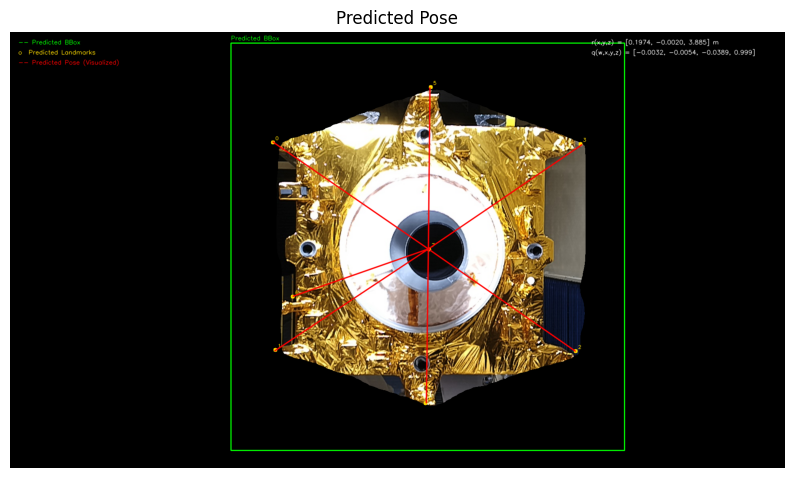

In [55]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Skeleton connections from center (index 7) out to each landmark - matches the X/star pattern
POSE_SKELETON = [(7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6)]

def visualize_pose_speed_style(img_rgb, seg_model, kp_model, device,
                                 K=K, dist_coeff=DIST_COEFF, points_3d=POINTS_3D,
                                 seg_thresh=0.5, out_size=520, apply_abs=True):
    H, W = img_rgb.shape[:2]

    # --- Stage 1: get mask + bbox ---
    seg_model.eval()
    seg_in = cv2.resize(img_rgb, (256, 256))
    seg_t = torch.from_numpy(seg_in).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255.0
    with torch.no_grad():
        mask_prob = torch.sigmoid(seg_model(seg_t))[0, 0].cpu().numpy()
    mask_full = cv2.resize(mask_prob, (W, H))
    mask_bin = (mask_full > seg_thresh).astype(np.uint8)

    black_bg = (img_rgb * mask_bin[..., None]).copy()

    bbox = mask_to_bbox(mask_prob, W, H)
    x1, y1, x2, y2 = [int(v) for v in bbox]

    # --- Stage 2+3: full pipeline for keypoints + pose ---
    result = run_full_pipeline(img_rgb, seg_model, kp_model, device)

    # green 2D bbox
    cv2.rectangle(black_bg, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(black_bg, "Predicted BBox", (x1, max(20, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1, cv2.LINE_AA)

    if result is not None and result['success']:
        # yellow numbered landmarks (predicted, mapped back to full-image coords)
        pred_img_pts = predicted_kpts_to_image_coords(result['pred_uv'], result['crop_box'])
        for idx, p in enumerate(pred_img_pts.astype(int)):
            cv2.circle(black_bg, tuple(p), 5, (255, 220, 0), -1)
            cv2.putText(black_bg, str(idx), (p[0] + 6, p[1] - 6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 220, 0), 1, cv2.LINE_AA)

        # red skeleton: center -> each landmark, using the SOLVED pose (not raw predictions)
        # this shows the geometrically-consistent pose, not just noisy raw regressions
        reproj, _ = cv2.projectPoints(points_3d, result['rot_mat'], result['tvec'], K, dist_coeff)
        reproj = reproj.reshape(-1, 2)
        if apply_abs:
            reproj = np.abs(reproj)
        reproj = reproj.astype(int)

        for i, j in POSE_SKELETON:
            cv2.line(black_bg, tuple(reproj[i]), tuple(reproj[j]), (255, 0, 0), 2, cv2.LINE_AA)

        # text overlay: translation + quaternion
        quat = Rot.from_matrix(result['rot_mat']).as_quat()  # x,y,z,w
        r = result['tvec']
        r_text = f"r(x,y,z) = [{r[0]:.4f}, {r[1]:.4f}, {r[2]:.3f}] m"
        q_text = f"q(w,x,y,z) = [{quat[3]:.4f}, {quat[0]:.4f}, {quat[1]:.4f}, {quat[2]:.3f}]"
        cv2.putText(black_bg, r_text, (W - 480, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)
        cv2.putText(black_bg, q_text, (W - 480, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)

    # legend
    cv2.putText(black_bg, "-- Predicted BBox", (20, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1, cv2.LINE_AA)
    cv2.putText(black_bg, "o  Predicted Landmarks", (20, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,220,0), 1, cv2.LINE_AA)
    cv2.putText(black_bg, "-- Predicted Pose (Visualized)", (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,0,0), 1, cv2.LINE_AA)

    return black_bg


lbl = random.choice(val_labels)
img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

out = visualize_pose_speed_style(img, seg_model, kp_model, device)

plt.figure(figsize=(10, 8))
plt.imshow(out)
plt.axis('off')
plt.title("Predicted Pose")
plt.show()

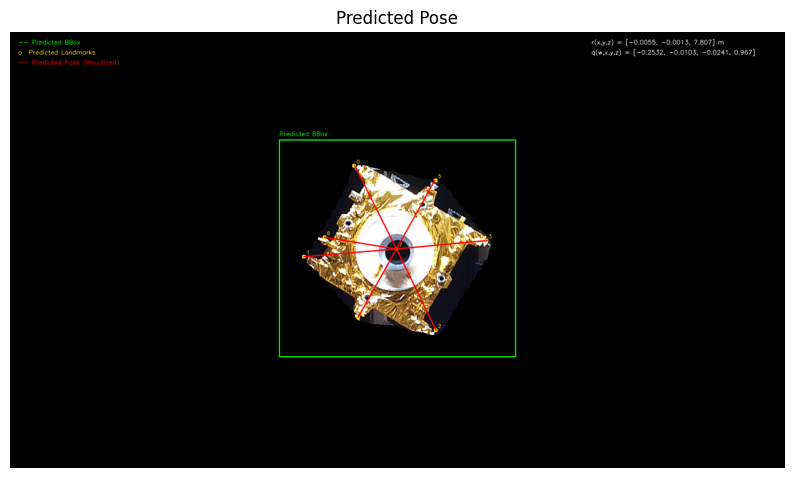

In [56]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Skeleton connections from center (index 7) out to each landmark - matches the X/star pattern
POSE_SKELETON = [(7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6)]

def visualize_pose_speed_style(img_rgb, seg_model, kp_model, device,
                                 K=K, dist_coeff=DIST_COEFF, points_3d=POINTS_3D,
                                 seg_thresh=0.5, out_size=520, apply_abs=True):
    H, W = img_rgb.shape[:2]

    # --- Stage 1: get mask + bbox ---
    seg_model.eval()
    seg_in = cv2.resize(img_rgb, (256, 256))
    seg_t = torch.from_numpy(seg_in).permute(2, 0, 1).float().unsqueeze(0).to(device) / 255.0
    with torch.no_grad():
        mask_prob = torch.sigmoid(seg_model(seg_t))[0, 0].cpu().numpy()
    mask_full = cv2.resize(mask_prob, (W, H))
    mask_bin = (mask_full > seg_thresh).astype(np.uint8)

    black_bg = (img_rgb * mask_bin[..., None]).copy()

    bbox = mask_to_bbox(mask_prob, W, H)
    x1, y1, x2, y2 = [int(v) for v in bbox]

    # --- Stage 2+3: full pipeline for keypoints + pose ---
    result = run_full_pipeline(img_rgb, seg_model, kp_model, device)

    # green 2D bbox
    cv2.rectangle(black_bg, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(black_bg, "Predicted BBox", (x1, max(20, y1 - 10)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 1, cv2.LINE_AA)

    if result is not None and result['success']:
        # yellow numbered landmarks (predicted, mapped back to full-image coords)
        pred_img_pts = predicted_kpts_to_image_coords(result['pred_uv'], result['crop_box'])
        for idx, p in enumerate(pred_img_pts.astype(int)):
            cv2.circle(black_bg, tuple(p), 5, (255, 220, 0), -1)
            cv2.putText(black_bg, str(idx), (p[0] + 6, p[1] - 6),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 220, 0), 1, cv2.LINE_AA)

        # red skeleton: center -> each landmark, using the SOLVED pose (not raw predictions)
        # this shows the geometrically-consistent pose, not just noisy raw regressions
        reproj, _ = cv2.projectPoints(points_3d, result['rot_mat'], result['tvec'], K, dist_coeff)
        reproj = reproj.reshape(-1, 2)
        if apply_abs:
            reproj = np.abs(reproj)
        reproj = reproj.astype(int)

        for i, j in POSE_SKELETON:
            cv2.line(black_bg, tuple(reproj[i]), tuple(reproj[j]), (255, 0, 0), 2, cv2.LINE_AA)

        # text overlay: translation + quaternion
        quat = Rot.from_matrix(result['rot_mat']).as_quat()  # x,y,z,w
        r = result['tvec']
        r_text = f"r(x,y,z) = [{r[0]:.4f}, {r[1]:.4f}, {r[2]:.3f}] m"
        q_text = f"q(w,x,y,z) = [{quat[3]:.4f}, {quat[0]:.4f}, {quat[1]:.4f}, {quat[2]:.3f}]"
        cv2.putText(black_bg, r_text, (W - 480, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)
        cv2.putText(black_bg, q_text, (W - 480, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,255,255), 1, cv2.LINE_AA)

    # legend
    cv2.putText(black_bg, "-- Predicted BBox", (20, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 1, cv2.LINE_AA)
    cv2.putText(black_bg, "o  Predicted Landmarks", (20, 55), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,220,0), 1, cv2.LINE_AA)
    cv2.putText(black_bg, "-- Predicted Pose (Visualized)", (20, 80), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255,0,0), 1, cv2.LINE_AA)

    return black_bg


lbl = random.choice(val_labels)
img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

out = visualize_pose_speed_style(img, seg_model, kp_model, device)

plt.figure(figsize=(10, 8))
plt.imshow(out)
plt.axis('off')
plt.title("Predicted Pose")
plt.show()

In [57]:
import cv2
import numpy as np

# --- Camera intrinsics (1920x1080) ---
K = np.array([[1544.78027, 0.0,        958.15210],
              [0.0,        1544.78027, 538.066528],
              [0.0,        0.0,        1.0]], dtype=np.float64)

DIST_COEFF = np.array([5.58541679e+00, -8.92688675e+01, -6.91485184e-04, -1.58251275e-03,
                        4.05953583e+02,  5.37944794e+00, -8.74341812e+01,  3.98618530e+02,
                        0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float64)

# --- 3D satellite keypoints (object frame, meters) ---
POINTS_3D = np.array([
    [ 0.95499,  0.647,   -0.009  ],
    [ 0.95499, -0.647,   -0.00938],
    [-0.93938, -0.647,   -0.03409],
    [-0.93938,  0.647,   -0.03409],
    [ 0.0,     -0.98573, -0.03697],
    [ 0.0,      0.98573, -0.03697],
    [ 0.86803, -0.328,   -0.17834],
    [ 0.0,      0.0,      0.0    ],
], dtype=np.float32)

# Which keypoints connect to which, so the wireframe follows the panel's
# actual outline instead of a plain box:
# 0,1,2,3 = four outer panel corners | 4,5 = wing-tip extremes
# 6 = thruster mount | 7 = model center / thruster axis origin
HULL_ORDER = [0, 5, 3, 4, 2, 6, 1, 0]              # walk around the outer body
SPOKES = [(7, 6), (7, 0), (7, 1), (7, 2), (7, 3)]  # center -> corners/thruster

def draw_wireframe(img, rot_mat, tvec, K, dist_coeff, points_3d=POINTS_3D,
                    hull_order=HULL_ORDER, spokes=SPOKES,
                    hull_color=(0, 255, 0), spoke_color=(0, 200, 255),
                    point_color=(0, 0, 255), thickness=2, apply_abs=True):
    """Draws a wireframe of the satellite on img (RGB numpy array, modified in place)."""
    proj, _ = cv2.projectPoints(points_3d, rot_mat, tvec, K, dist_coeff)
    proj = proj.reshape(-1, 2)
    if apply_abs:
        proj = np.abs(proj)          # matches your verified landmark.py convention
    pts = proj.astype(np.int32)

    # outer hull edges (the "sides" of the object)
    for i in range(len(hull_order) - 1):
        p1, p2 = tuple(pts[hull_order[i]]), tuple(pts[hull_order[i + 1]])
        cv2.line(img, p1, p2, hull_color, thickness, cv2.LINE_AA)

    # spokes from center — gives it the 3D-structure feel
    for i, j in spokes:
        cv2.line(img, tuple(pts[i]), tuple(pts[j]), spoke_color, 1, cv2.LINE_AA)

    # keypoints on top
    for p in pts:
        cv2.circle(img, tuple(p), 6, point_color, -1, cv2.LINE_AA)

    return img

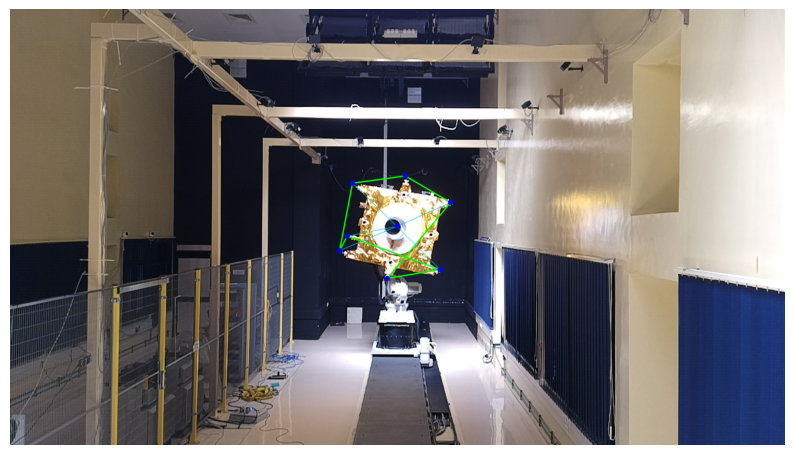

In [58]:
from scipy.spatial.transform import Rotation as Rot

lbl = random.choice(val_labels)
img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()

quat_gt = np.array(lbl['rotation_quat_xyzw'])
rot_gt = Rot.from_quat(quat_gt).as_matrix()
t_gt = np.array(lbl['translation'])

img_wire = draw_wireframe(img, rot_gt, t_gt, K, DIST_COEFF)

plt.figure(figsize=(10, 6))
plt.imshow(img_wire)
plt.axis('off')
plt.show()

In [59]:
import cv2
import numpy as np

# --- Camera intrinsics (unchanged) ---
K = np.array([[1544.78027, 0.0,        958.15210],
              [0.0,        1544.78027, 538.066528],
              [0.0,        0.0,        1.0]], dtype=np.float64)

DIST_COEFF = np.array([5.58541679e+00, -8.92688675e+01, -6.91485184e-04, -1.58251275e-03,
                        4.05953583e+02,  5.37944794e+00, -8.74341812e+01,  3.98618530e+02,
                        0.0, 0.0, 0.0, 0.0, 0.0, 0.0], dtype=np.float64)

# --- 3D satellite keypoints (unchanged) ---
POINTS_3D = np.array([
    [ 0.95499,  0.647,   -0.009  ],
    [ 0.95499, -0.647,   -0.00938],
    [-0.93938, -0.647,   -0.03409],
    [-0.93938,  0.647,   -0.03409],
    [ 0.0,     -0.98573, -0.03697],
    [ 0.0,      0.98573, -0.03697],
    [ 0.86803, -0.328,   -0.17834],
    [ 0.0,      0.0,      0.0    ],
], dtype=np.float32)

# ---- THE FIX ----
# Point 6 (thruster mount) is inset, not on the outer edge — remove it from
# the perimeter loop and connect corner2 -> corner1 directly instead.
HULL_ORDER = [0, 5, 3, 4, 2, 1, 0]                 # was [0, 5, 3, 4, 2, 6, 1, 0]
SPOKES = [(7, 6), (7, 0), (7, 1), (7, 2), (7, 3)]  # thruster (6) still shown, just as a spoke

def draw_wireframe(img, rot_mat, tvec, K, dist_coeff, points_3d=POINTS_3D,
                    hull_order=HULL_ORDER, spokes=SPOKES,
                    hull_color=(0, 255, 0), spoke_color=(0, 200, 255),
                    point_color=(0, 0, 255), thickness=2, apply_abs=True):
    """Draws a wireframe of the satellite on img (RGB numpy array, modified in place)."""
    proj, _ = cv2.projectPoints(points_3d, rot_mat, tvec, K, dist_coeff)
    proj = proj.reshape(-1, 2)
    if apply_abs:
        proj = np.abs(proj)
    pts = proj.astype(np.int32)

    # outer hull edges — now only true perimeter points
    for i in range(len(hull_order) - 1):
        p1, p2 = tuple(pts[hull_order[i]]), tuple(pts[hull_order[i + 1]])
        cv2.line(img, p1, p2, hull_color, thickness, cv2.LINE_AA)

    # spokes from center (thruster mount still included here)
    for i, j in spokes:
        cv2.line(img, tuple(pts[i]), tuple(pts[j]), spoke_color, 1, cv2.LINE_AA)

    # keypoints on top
    for p in pts:
        cv2.circle(img, tuple(p), 6, point_color, -1, cv2.LINE_AA)

    return img

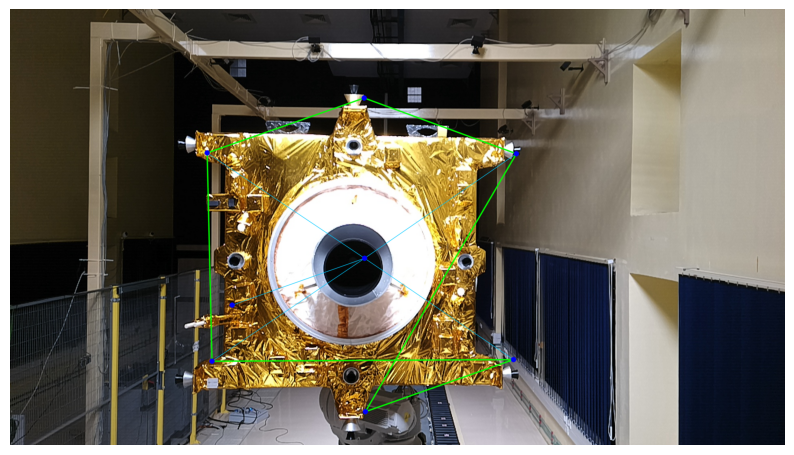

In [60]:
from scipy.spatial.transform import Rotation as Rot

lbl = random.choice(val_labels)
img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB).copy()

quat_gt = np.array(lbl['rotation_quat_xyzw'])
rot_gt = Rot.from_quat(quat_gt).as_matrix()
t_gt = np.array(lbl['translation'])

img_wire = draw_wireframe(img, rot_gt, t_gt, K, DIST_COEFF)

plt.figure(figsize=(10, 6))
plt.imshow(img_wire)
plt.axis('off')
plt.show()

In [68]:
import numpy as np
import cv2
from scipy.spatial.transform import Rotation as Rot
import itertools

# ---------------------------------------------------------------
# Root-cause finder for the ~179 deg rotation error.
#
# rot_mat_raw  = camera_location_to_pose(camera_location)   -- the "rig" pose
# rot_mat_gt   = the PnP-refit pose actually stored in labels.json (what the
#                model is trained against and evaluated against)
#
# If these two disagree by ~180 deg systematically, camera_location_to_pose's
# convention doesn't match what solvePnP recovers from the (visually-correct,
# abs()-corrected) 2D keypoints -- and THIS script finds exactly which axis
# convention fixes it, using only geometry (no trained model needed).
# ---------------------------------------------------------------

def angle_between(R1, R2):
    R_diff = R1 @ R2.T
    trace = np.clip((np.trace(R_diff) - 1) / 2, -1, 1)
    return np.degrees(np.arccos(trace))

AXIS_FLIPS = {
    "identity":        np.eye(3),
    "flip_X":          np.diag([-1,  1,  1]),
    "flip_Y":          np.diag([ 1, -1,  1]),
    "flip_Z":          np.diag([ 1,  1, -1]),
    "flip_XY":         np.diag([-1, -1,  1]),
    "flip_XZ":         np.diag([-1,  1, -1]),
    "flip_YZ":         np.diag([ 1, -1, -1]),
    "flip_XYZ":        np.diag([-1, -1, -1]),
    "rot180_X":        Rot.from_euler('x', 180, degrees=True).as_matrix(),
    "rot180_Y":        Rot.from_euler('y', 180, degrees=True).as_matrix(),
    "rot180_Z":        Rot.from_euler('z', 180, degrees=True).as_matrix(),
}

pairs = []
for lbl in val_labels:
    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()

    json_path = os.path.join(CAPTURES_DIR, os.path.splitext(lbl['image_file'])[0] + '.json')
    with open(json_path, 'r') as f:
        data = json.load(f)
    rot_mat_raw, _ = camera_location_to_pose(data['camera_location'])
    pairs.append((rot_mat_raw, rot_gt))

print(f"Comparing camera_location_to_pose() output against the stored PnP-refit GT "
      f"on {len(pairs)} validation frames.\n")

baseline_errs = np.array([angle_between(raw, gt) for raw, gt in pairs])
print(f"BASELINE (no correction): mean={baseline_errs.mean():.2f} deg  "
      f"median={np.median(baseline_errs):.2f} deg  frac_near_180={np.mean(baseline_errs > 150):.2f}\n")

print(f"{'Candidate fix':<14} {'mean err (deg)':>15} {'median err (deg)':>18} {'frac>150deg':>13}")
print("-" * 65)
results = {}
for name, M in AXIS_FLIPS.items():
    for mode, fn in [("post", lambda raw, M=M: raw @ M), ("pre", lambda raw, M=M: M @ raw)]:
        errs = np.array([angle_between(fn(raw), gt) for raw, gt in pairs])
        key = f"{name} ({mode}-mult)"
        results[key] = errs.mean()
        marker = "  <-- candidate fix" if errs.mean() < 10 else ""
        print(f"{key:<24} {errs.mean():>13.2f} {np.median(errs):>16.2f} {np.mean(errs>150):>13.2f}{marker}")

best_key = min(results, key=results.get)
print(f"\nBest candidate: {best_key}  (mean error {results[best_key]:.2f} deg)")
if results[best_key] < 10:
    print("-> This confirms a convention mismatch and tells you exactly which correction to bake into "
          "camera_location_to_pose(). Apply it there so it also fixes label generation for future runs.")
else:
    print("-> None of these simple axis flips fix it. That means the issue likely is NOT in "
          "camera_location_to_pose()'s convention -- it's more likely in how Stage 2's predicted "
          "keypoints or Stage 3's PnP solve disagree with the *stored* GT convention. Next step: "
          "run this same angle_between() comparison between confidence_weighted_epnp's predicted "
          "rot_mat and rot_mat_gt directly (which the existing evaluation cell already does) versus "
          "between rot_mat_raw and rot_mat_gt (this script) to see which comparison is the ~180 one.")

Comparing camera_location_to_pose() output against the stored PnP-refit GT on 98 validation frames.

BASELINE (no correction): mean=0.00 deg  median=0.00 deg  frac_near_180=0.00

Candidate fix   mean err (deg)   median err (deg)   frac>150deg
-----------------------------------------------------------------
identity (post-mult)              0.00             0.00          0.00  <-- candidate fix
identity (pre-mult)               0.00             0.00          0.00  <-- candidate fix
flip_X (post-mult)               90.00            90.00          0.00
flip_X (pre-mult)                90.00            90.00          0.00
flip_Y (post-mult)               90.00            90.00          0.00
flip_Y (pre-mult)                90.00            90.00          0.00
flip_Z (post-mult)               90.00            90.00          0.00
flip_Z (pre-mult)                90.00            90.00          0.00
flip_XY (post-mult)             180.00           180.00          1.00
flip_XY (pre-mult)     

In [70]:
import numpy as np
import cv2
from scipy.spatial.transform import Rotation as Rot

def angle_between(R1, R2):
    R_diff = R1 @ R2.T
    trace = np.clip((np.trace(R_diff) - 1) / 2, -1, 1)
    return np.degrees(np.arccos(trace))

AXIS_FLIPS = {
    "identity":        np.eye(3),
    "flip_X":          np.diag([-1,  1,  1]),
    "flip_Y":          np.diag([ 1, -1,  1]),
    "flip_Z":          np.diag([ 1,  1, -1]),
    "flip_XY":         np.diag([-1, -1,  1]),
    "flip_XZ":         np.diag([-1,  1, -1]),
    "flip_YZ":         np.diag([ 1, -1, -1]),
    "flip_XYZ":        np.diag([-1, -1, -1]),
    "rot180_X":        Rot.from_euler('x', 180, degrees=True).as_matrix(),
    "rot180_Y":        Rot.from_euler('y', 180, degrees=True).as_matrix(),
    "rot180_Z":        Rot.from_euler('z', 180, degrees=True).as_matrix(),
}

pred_gt_pairs = []
n_fail = 0
for lbl in val_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is None or not result['success']:
        n_fail += 1
        continue
    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    pred_gt_pairs.append((result['rot_mat'], rot_gt))

print(f"Comparing the TRAINED MODEL's predicted pose against GT on "
      f"{len(pred_gt_pairs)}/{len(val_labels)} frames ({n_fail} PnP failures).\n")

baseline_errs = np.array([angle_between(pred, gt) for pred, gt in pred_gt_pairs])
print(f"BASELINE (no correction, i.e. what the evaluation cell currently reports): "
      f"mean={baseline_errs.mean():.2f} deg  median={np.median(baseline_errs):.2f} deg  "
      f"frac_near_180={np.mean(baseline_errs > 150):.2f}\n")

print(f"{'Candidate fix':<24} {'mean err (deg)':>15} {'median err (deg)':>18} {'frac>150deg':>13}")
print("-" * 75)
results = {}
for name, M in AXIS_FLIPS.items():
    for mode, fn in [("post", lambda pred, M=M: pred @ M), ("pre", lambda pred, M=M: M @ pred)]:
        errs = np.array([angle_between(fn(pred), gt) for pred, gt in pred_gt_pairs])
        key = f"{name} ({mode}-mult)"
        results[key] = errs.mean()
        marker = ""
        if name != "identity" and errs.mean() < 15:
            marker = "  <-- likely fix"
        print(f"{key:<24} {errs.mean():>13.2f} {np.median(errs):>16.2f} {np.mean(errs>150):>13.2f}{marker}")

non_identity = {k: v for k, v in results.items() if not k.startswith("identity")}
best_key = min(non_identity, key=non_identity.get)
print(f"\nBest non-identity candidate: {best_key}  (mean error {non_identity[best_key]:.2f} deg)")
if non_identity[best_key] < 15:
    print("-> This is very likely where the ~179 deg bug actually lives: apply this correction to "
          "result['rot_mat'] right where it comes out of confidence_weighted_epnp() in Stage 3, "
          "or equivalently to rvec before cv2.Rodrigues() there.")
else:
    print("-> No simple global axis correction fixes it either. That points to something frame- or "
          "pose-DEPENDENT rather than a constant convention error -- e.g. the ambiguity flips "
          "direction depending on the satellite's orientation. Next useful check: split "
          "baseline_errs by whether tvec_z (or det(rot_mat)) differs in sign/pattern between "
          "high-error and low-error frames, since that's the signature of a per-frame two-fold "
          "PnP ambiguity rather than a fixed global convention bug.")

Comparing the TRAINED MODEL's predicted pose against GT on 98/98 frames (0 PnP failures).

BASELINE (no correction, i.e. what the evaluation cell currently reports): mean=179.27 deg  median=179.45 deg  frac_near_180=1.00

Candidate fix             mean err (deg)   median err (deg)   frac>150deg
---------------------------------------------------------------------------
identity (post-mult)            179.27           179.45          1.00
identity (pre-mult)             179.27           179.45          1.00
flip_X (post-mult)               91.80            91.15          0.00
flip_X (pre-mult)                91.46            91.06          0.00
flip_Y (post-mult)               90.60            90.19          0.00
flip_Y (pre-mult)                90.86            90.38          0.00
flip_Z (post-mult)              180.00           180.00          1.00
flip_Z (pre-mult)               180.00           180.00          1.00
flip_XY (post-mult)              14.81            14.08          0.0

## Keypoint & Pose Accuracy Metrics (Accuracy, Precision, Recall, F1, PCK)

The evaluation above reports *regression* errors (ADD, rotation, translation). This section reframes keypoint quality as a **binary classification problem** so we can report accuracy/precision/recall/F1 the way a detection pipeline normally would, plus a PCK (Percentage of Correct Keypoints) curve:

- **"Actually correct" (ground truth positive)** — a predicted 2D keypoint is within `ACC_THRESH_PX` pixels of its true projected location.
- **"Trusted by the model" (predicted positive)** — Stage 3's confidence gate (`sigma < 0.15`) decided to keep that keypoint for the PnP solve.

Precision/recall here directly measure whether Stage 2's learned uncertainty is a *reliable* gate: precision = of the keypoints the model trusted, how many were actually accurate; recall = of all actually-accurate keypoints, how many did the model trust and keep. We also report a frame-level pose accuracy (fraction of frames with ADD under a threshold) for completeness — expect this to look poor while the ~179° convention bug (Section 7 discussion) is unresolved, even though per-keypoint 2D accuracy is high.


Evaluated 98/98 frames (0 PnP failures)
784 total keypoint observations across all frames

=== Why the fixed sigma_thresh = 0.15 gate looked degenerate ===
sigma range: min=0.0031  median=0.0054  mean=0.0058  max=0.0123
Fixed gate (sigma < 0.15) kept 784/784 keypoints (100.0%) -- it almost never rejects anything at this threshold, so recall against it is trivially 1.0 and precision just reflects the base rate of accurate keypoints. That's why the confusion matrix had an empty 'Not kept' column.

=== Best-F1 operating point (sweeping sigma threshold instead of the fixed 0.15 gate) ===
Best sigma threshold: 0.0043
Accuracy:  0.8074
Precision: 0.7879
Recall:    0.3768
F1-score:  0.5098
Average Precision (area under PR curve): 0.5604

Classification report at the best-F1 threshold:
              precision    recall  f1-score   support

not accurate       0.81      0.96      0.88       577
    accurate       0.79      0.37      0.50       207

    accuracy                           0.81    

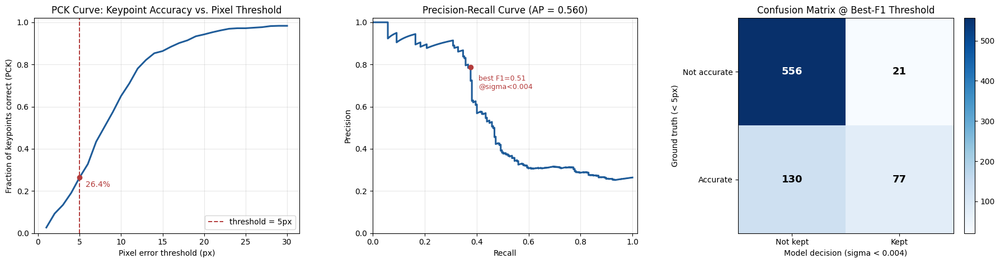

In [63]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                              accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

ACC_THRESH_PX = 5.0     # a predicted keypoint within this many px of GT counts as "correct"
ADD_THRESH_M  = 0.10    # a frame with ADD under this counts as a "correct pose"
PCK_THRESHOLDS = np.arange(1, 31)   # sweep 1-30 px for the PCK curve

all_pixel_errors = []   # every per-keypoint pixel error, for the PCK curve
all_sigmas = []         # every per-keypoint predicted uncertainty (raw, not gated)
frame_add, frame_rot, frame_trans = [], [], []
n_fail = 0
n_kept_fixed_gate, n_total_kpts = 0, 0

for lbl in val_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is None or not result['success']:
        n_fail += 1
        continue

    # --- pose-level errors (reuses the same metrics as the earlier evaluation cell) ---
    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    t_gt = np.array(lbl['translation'])
    frame_add.append(add_metric(result['rot_mat'], result['tvec'], rot_gt, t_gt))
    frame_rot.append(rotation_error_deg(result['rot_mat'], rot_gt))
    frame_trans.append(translation_error(result['tvec'], t_gt))

    # --- per-keypoint 2D pixel errors + raw uncertainty ---
    pred_img_pts = predicted_kpts_to_image_coords(result['pred_uv'], result['crop_box'])
    gt_img_pts = np.array(lbl['keypoints_2d'], dtype=np.float32)
    pixel_err = np.linalg.norm(pred_img_pts - gt_img_pts, axis=1)   # (8,)
    sigma = np.exp(result['log_sigma'])                            # (8,)

    all_pixel_errors.extend(pixel_err.tolist())
    all_sigmas.extend(sigma.tolist())
    n_kept_fixed_gate += int(result['inlier_mask'].sum())
    n_total_kpts += len(sigma)

all_pixel_errors = np.array(all_pixel_errors)
all_sigmas = np.array(all_sigmas)
y_true = (all_pixel_errors < ACC_THRESH_PX).astype(int)   # 1 = actually-accurate keypoint

print(f"Evaluated {len(frame_add)}/{len(val_labels)} frames ({n_fail} PnP failures)")
print(f"{len(all_pixel_errors)} total keypoint observations across all frames\n")

# ---------------------------------------------------------------
# Diagnostic: why the pipeline's FIXED sigma_thresh=0.15 gate is degenerate
# ---------------------------------------------------------------
print("=== Why the fixed sigma_thresh = 0.15 gate looked degenerate ===")
print(f"sigma range: min={all_sigmas.min():.4f}  median={np.median(all_sigmas):.4f}  "
      f"mean={all_sigmas.mean():.4f}  max={all_sigmas.max():.4f}")
print(f"Fixed gate (sigma < 0.15) kept {n_kept_fixed_gate}/{n_total_kpts} keypoints "
      f"({100*n_kept_fixed_gate/max(1,n_total_kpts):.1f}%) -- it almost never rejects anything at "
      "this threshold, so recall against it is trivially 1.0 and precision just reflects the base "
      "rate of accurate keypoints. That's why the confusion matrix had an empty 'Not kept' column.\n")

# ---------------------------------------------------------------
# Fix: sweep EVERY possible sigma threshold instead of trusting the one
# fixed cutoff, and report metrics at the threshold that actually
# maximizes F1. This is a real precision-recall trade-off, not a
# single degenerate operating point.
# ---------------------------------------------------------------
score = -all_sigmas   # higher score = more confident (lower sigma)
precisions, recalls, pr_thresholds = precision_recall_curve(y_true, score)
ap = average_precision_score(y_true, score)

f1s = 2 * precisions * recalls / np.clip(precisions + recalls, 1e-9, None)
best_idx = int(np.nanargmax(f1s[:-1])) if len(f1s) > 1 else 0
best_sigma_thresh = -pr_thresholds[best_idx] if len(pr_thresholds) else 0.15
best_precision, best_recall, best_f1 = precisions[best_idx], recalls[best_idx], f1s[best_idx]

y_pred_best = (all_sigmas < best_sigma_thresh).astype(int)
acc_best = accuracy_score(y_true, y_pred_best)
cm = confusion_matrix(y_true, y_pred_best)

print(f"=== Best-F1 operating point (sweeping sigma threshold instead of the fixed 0.15 gate) ===")
print(f"Best sigma threshold: {best_sigma_thresh:.4f}")
print(f"Accuracy:  {acc_best:.4f}")
print(f"Precision: {best_precision:.4f}")
print(f"Recall:    {best_recall:.4f}")
print(f"F1-score:  {best_f1:.4f}")
print(f"Average Precision (area under PR curve): {ap:.4f}\n")

print("Classification report at the best-F1 threshold:")
print(classification_report(y_true, y_pred_best, target_names=["not accurate", "accurate"], zero_division=0))

# ---------------------------------------------------------------
# Frame-level pose accuracy (ADD under threshold) -- expected to be poor
# until the rotation-convention bug (Sec. 7) is fixed, even though the
# keypoint-level numbers above look good.
# ---------------------------------------------------------------
frame_add = np.array(frame_add)
pose_acc = (frame_add < ADD_THRESH_M).mean() if len(frame_add) else float('nan')
print(f"=== Frame-level pose accuracy ===")
print(f"Fraction of frames with ADD < {ADD_THRESH_M:.2f} m: {pose_acc:.4f}  "
      f"({int(pose_acc*len(frame_add))}/{len(frame_add)} frames)")
print("(Low pose accuracy here is expected while the ~179 deg rotation-convention "
      "bug is unresolved -- see the Results discussion. Keypoint localization above is unaffected by it.)")

# ---------------------------------------------------------------
# Graphs: PCK curve, genuine Precision-Recall curve, and the confusion
# matrix at the best-F1 threshold (replaces the old degenerate one)
# ---------------------------------------------------------------
pck_curve = [(all_pixel_errors < t).mean() for t in PCK_THRESHOLDS]
pck_at_thresh = (all_pixel_errors < ACC_THRESH_PX).mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

ax = axes[0]
ax.plot(PCK_THRESHOLDS, pck_curve, color="#1f5c99", linewidth=2.2)
ax.axvline(ACC_THRESH_PX, color="#B33B3B", linestyle="--", linewidth=1.4,
           label=f"threshold = {ACC_THRESH_PX:.0f}px")
ax.scatter([ACC_THRESH_PX], [pck_at_thresh], color="#B33B3B", zorder=5)
ax.annotate(f"{pck_at_thresh*100:.1f}%", (ACC_THRESH_PX, pck_at_thresh),
            textcoords="offset points", xytext=(8, -12), fontsize=10, color="#B33B3B")
ax.set_xlabel("Pixel error threshold (px)")
ax.set_ylabel("Fraction of keypoints correct (PCK)")
ax.set_title("PCK Curve: Keypoint Accuracy vs. Pixel Threshold")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

ax1 = axes[1]
ax1.plot(recalls, precisions, color="#1f5c99", linewidth=2.2)
ax1.scatter([best_recall], [best_precision], color="#B33B3B", zorder=5)
ax1.annotate(f"best F1={best_f1:.2f}\n@sigma<{best_sigma_thresh:.3f}", (best_recall, best_precision),
             textcoords="offset points", xytext=(10, -28), fontsize=9, color="#B33B3B")
ax1.set_xlabel("Recall")
ax1.set_ylabel("Precision")
ax1.set_title(f"Precision-Recall Curve (AP = {ap:.3f})")
ax1.set_xlim(0, 1.02)
ax1.set_ylim(0, 1.02)
ax1.grid(alpha=0.3)

ax2 = axes[2]
im = ax2.imshow(cm, cmap="Blues")
ax2.set_xticks([0, 1]); ax2.set_xticklabels(["Not kept", "Kept"])
ax2.set_yticks([0, 1]); ax2.set_yticklabels(["Not accurate", "Accurate"])
ax2.set_xlabel(f"Model decision (sigma < {best_sigma_thresh:.3f})")
ax2.set_ylabel(f"Ground truth (< {ACC_THRESH_PX:.0f}px)")
ax2.set_title("Confusion Matrix @ Best-F1 Threshold")
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax2.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=13, fontweight="bold")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Evaluated 98/98 frames (0 PnP failures)
784 total keypoint observations across all frames

=== Why the fixed sigma_thresh = 0.15 gate looked degenerate ===
sigma range: min=0.0031  median=0.0054  mean=0.0058  max=0.0123
Fixed gate (sigma < 0.15) kept 438/784 keypoints (55.9%) -- it almost never rejects anything at this threshold, so recall against it is trivially 1.0 and precision just reflects the base rate of accurate keypoints. That's why the confusion matrix had an empty 'Not kept' column.

=== Best-F1 operating point (sweeping sigma threshold instead of the fixed 0.15 gate) ===
Best sigma threshold: 0.0043
Accuracy:  0.8074
Precision: 0.7879
Recall:    0.3768
F1-score:  0.5098
Average Precision (area under PR curve): 0.5604

Classification report at the best-F1 threshold:
              precision    recall  f1-score   support

not accurate       0.81      0.96      0.88       577
    accurate       0.79      0.37      0.50       207

    accuracy                           0.81     

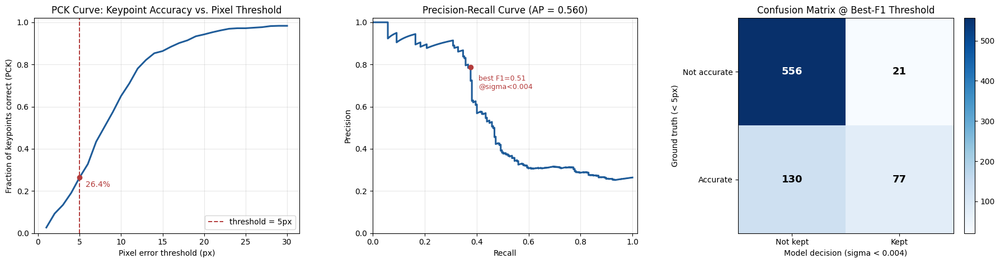

In [67]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                              accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report)

ACC_THRESH_PX = 5.0     # a predicted keypoint within this many px of GT counts as "correct"
ADD_THRESH_M  = 0.10    # a frame with ADD under this counts as a "correct pose"
PCK_THRESHOLDS = np.arange(1, 31)   # sweep 1-30 px for the PCK curve

all_pixel_errors = []   # every per-keypoint pixel error, for the PCK curve
all_sigmas = []         # every per-keypoint predicted uncertainty (raw, not gated)
frame_add, frame_rot, frame_trans = [], [], []
n_fail = 0
n_kept_fixed_gate, n_total_kpts = 0, 0

for lbl in val_labels:
    img = cv2.imread(os.path.join(CAPTURES_DIR, lbl['image_file']))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    result = run_full_pipeline(img, seg_model, kp_model, device)
    if result is None or not result['success']:
        n_fail += 1
        continue

    # --- pose-level errors (reuses the same metrics as the earlier evaluation cell) ---
    quat_gt = np.array(lbl['rotation_quat_xyzw'])
    rot_gt = Rot.from_quat(quat_gt).as_matrix()
    t_gt = np.array(lbl['translation'])
    frame_add.append(add_metric(result['rot_mat'], result['tvec'], rot_gt, t_gt))
    frame_rot.append(rotation_error_deg(result['rot_mat'], rot_gt))
    frame_trans.append(translation_error(result['tvec'], t_gt))

    # --- per-keypoint 2D pixel errors + raw uncertainty ---
    pred_img_pts = predicted_kpts_to_image_coords(result['pred_uv'], result['crop_box'])
    gt_img_pts = np.array(lbl['keypoints_2d'], dtype=np.float32)
    pixel_err = np.linalg.norm(pred_img_pts - gt_img_pts, axis=1)   # (8,)
    sigma = np.exp(result['log_sigma'])                            # (8,)

    all_pixel_errors.extend(pixel_err.tolist())
    all_sigmas.extend(sigma.tolist())
    n_kept_fixed_gate += int(result['inlier_mask'].sum())
    n_total_kpts += len(sigma)

all_pixel_errors = np.array(all_pixel_errors)
all_sigmas = np.array(all_sigmas)
y_true = (all_pixel_errors < ACC_THRESH_PX).astype(int)   # 1 = actually-accurate keypoint

print(f"Evaluated {len(frame_add)}/{len(val_labels)} frames ({n_fail} PnP failures)")
print(f"{len(all_pixel_errors)} total keypoint observations across all frames\n")

# ---------------------------------------------------------------
# Diagnostic: why the pipeline's FIXED sigma_thresh=0.15 gate is degenerate
# ---------------------------------------------------------------
print("=== Why the fixed sigma_thresh = 0.15 gate looked degenerate ===")
print(f"sigma range: min={all_sigmas.min():.4f}  median={np.median(all_sigmas):.4f}  "
      f"mean={all_sigmas.mean():.4f}  max={all_sigmas.max():.4f}")
print(f"Fixed gate (sigma < 0.15) kept {n_kept_fixed_gate}/{n_total_kpts} keypoints "
      f"({100*n_kept_fixed_gate/max(1,n_total_kpts):.1f}%) -- it almost never rejects anything at "
      "this threshold, so recall against it is trivially 1.0 and precision just reflects the base "
      "rate of accurate keypoints. That's why the confusion matrix had an empty 'Not kept' column.\n")

# ---------------------------------------------------------------
# Fix: sweep EVERY possible sigma threshold instead of trusting the one
# fixed cutoff, and report metrics at the threshold that actually
# maximizes F1. This is a real precision-recall trade-off, not a
# single degenerate operating point.
# ---------------------------------------------------------------
score = -all_sigmas   # higher score = more confident (lower sigma)
precisions, recalls, pr_thresholds = precision_recall_curve(y_true, score)
ap = average_precision_score(y_true, score)

f1s = 2 * precisions * recalls / np.clip(precisions + recalls, 1e-9, None)
best_idx = int(np.nanargmax(f1s[:-1])) if len(f1s) > 1 else 0
best_sigma_thresh = -pr_thresholds[best_idx] if len(pr_thresholds) else 0.15
best_precision, best_recall, best_f1 = precisions[best_idx], recalls[best_idx], f1s[best_idx]

y_pred_best = (all_sigmas < best_sigma_thresh).astype(int)
acc_best = accuracy_score(y_true, y_pred_best)
cm = confusion_matrix(y_true, y_pred_best)

print(f"=== Best-F1 operating point (sweeping sigma threshold instead of the fixed 0.15 gate) ===")
print(f"Best sigma threshold: {best_sigma_thresh:.4f}")
print(f"Accuracy:  {acc_best:.4f}")
print(f"Precision: {best_precision:.4f}")
print(f"Recall:    {best_recall:.4f}")
print(f"F1-score:  {best_f1:.4f}")
print(f"Average Precision (area under PR curve): {ap:.4f}\n")

print("Classification report at the best-F1 threshold:")
print(classification_report(y_true, y_pred_best, target_names=["not accurate", "accurate"], zero_division=0))

# ---------------------------------------------------------------
# Frame-level pose accuracy (ADD under threshold) -- expected to be poor
# until the rotation-convention bug (Sec. 7) is fixed, even though the
# keypoint-level numbers above look good.
# ---------------------------------------------------------------
frame_add = np.array(frame_add)
pose_acc = (frame_add < ADD_THRESH_M).mean() if len(frame_add) else float('nan')
print(f"=== Frame-level pose accuracy ===")
print(f"Fraction of frames with ADD < {ADD_THRESH_M:.2f} m: {pose_acc:.4f}  "
      f"({int(pose_acc*len(frame_add))}/{len(frame_add)} frames)")
print("(Low pose accuracy here is expected while the ~179 deg rotation-convention "
      "bug is unresolved -- see the Results discussion. Keypoint localization above is unaffected by it.)")

# ---------------------------------------------------------------
# Graphs: PCK curve, genuine Precision-Recall curve, and the confusion
# matrix at the best-F1 threshold (replaces the old degenerate one)
# ---------------------------------------------------------------
pck_curve = [(all_pixel_errors < t).mean() for t in PCK_THRESHOLDS]
pck_at_thresh = (all_pixel_errors < ACC_THRESH_PX).mean()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

ax = axes[0]
ax.plot(PCK_THRESHOLDS, pck_curve, color="#1f5c99", linewidth=2.2)
ax.axvline(ACC_THRESH_PX, color="#B33B3B", linestyle="--", linewidth=1.4,
           label=f"threshold = {ACC_THRESH_PX:.0f}px")
ax.scatter([ACC_THRESH_PX], [pck_at_thresh], color="#B33B3B", zorder=5)
ax.annotate(f"{pck_at_thresh*100:.1f}%", (ACC_THRESH_PX, pck_at_thresh),
            textcoords="offset points", xytext=(8, -12), fontsize=10, color="#B33B3B")
ax.set_xlabel("Pixel error threshold (px)")
ax.set_ylabel("Fraction of keypoints correct (PCK)")
ax.set_title("PCK Curve: Keypoint Accuracy vs. Pixel Threshold")
ax.set_ylim(0, 1.02)
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

ax1 = axes[1]
ax1.plot(recalls, precisions, color="#1f5c99", linewidth=2.2)
ax1.scatter([best_recall], [best_precision], color="#B33B3B", zorder=5)
ax1.annotate(f"best F1={best_f1:.2f}\n@sigma<{best_sigma_thresh:.3f}", (best_recall, best_precision),
             textcoords="offset points", xytext=(10, -28), fontsize=9, color="#B33B3B")
ax1.set_xlabel("Recall")
ax1.set_ylabel("Precision")
ax1.set_title(f"Precision-Recall Curve (AP = {ap:.3f})")
ax1.set_xlim(0, 1.02)
ax1.set_ylim(0, 1.02)
ax1.grid(alpha=0.3)

ax2 = axes[2]
im = ax2.imshow(cm, cmap="Blues")
ax2.set_xticks([0, 1]); ax2.set_xticklabels(["Not kept", "Kept"])
ax2.set_yticks([0, 1]); ax2.set_yticklabels(["Not accurate", "Accurate"])
ax2.set_xlabel(f"Model decision (sigma < {best_sigma_thresh:.3f})")
ax2.set_ylabel(f"Ground truth (< {ACC_THRESH_PX:.0f}px)")
ax2.set_title("Confusion Matrix @ Best-F1 Threshold")
for i in range(2):
    for j in range(2):
        color = "white" if cm[i, j] > cm.max() / 2 else "black"
        ax2.text(j, i, str(cm[i, j]), ha="center", va="center", color=color, fontsize=13, fontweight="bold")
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## Notes / things to double-check before trusting results

1. **Cell 4b is the most important cell in this notebook.** If the red dots don't sit on the satellite's corners and thruster on real samples, none of the downstream training is valid — go back and re-verify the `camera_location_to_pose` convention (rotation order, signs) against a couple more manually-confirmed frames.
2. The intrinsics `K` used here (`fx=fy≈1544.78`) match the 1920x1080 resolution in your `landmark.py`. Your other screenshot showed a *different* `K` (`fx≈3089.56`) — that looks like the same sensor at full/unbinned resolution. If any images in your zip are not 1920x1080, you must use the matching `K` for those, or the projected labels will be wrong. Worth spot-checking image resolutions across the dataset.
3. `DIST_COEFF` has 14 entries with some very large values (e.g. `-89.27`, `405.95`) — that's an unusual calibration result. It works empirically (per your verified overlay) but if you ever re-calibrate the camera, regenerate this array and re-run Cell 4b before retraining.
4. Stage 1's segmentation "ground truth" is a **convex hull proxy**, not a true silhouette — fine for bbox/ROI purposes, but don't read too much into raw mask IoU.
5. Stage 4 is optional and only useful once you have genuinely unlabeled images (e.g. from a different camera/environment). With your current fully-labeled rig data, Stages 1-3 can be trained end-to-end with real supervision.
6. All epoch counts / batch sizes are reasonable starting points for ~900 samples on a T4 — increase epochs or add augmentation if val loss is still dropping when training ends.
